# Phase 1 & 2 — YOLOv8 Baseline Training (PPE Detection)
### Research-Grade Notebook

---


## Execution Order

```
Cell 0  →  STOP current run if training from ep1 again (run this first!)
Cell 1  →  Drive mount + directory setup
Cell 2  →  Install dependencies + GPU check
Cell 3  →  Dataset download + class distribution audit
Cell 4  →  Experiment 1: YOLOv8n (resume-safe, Drive-native)
Cell 5  →  Experiment 2: YOLOv8s (resume-safe)
Cell 6  →  Metrics extraction + per-class AP
Cell 7  →  Training curve plots
Cell 8  →  Artifact display (confusion matrix, PR curve, etc.)
Cell 9  →  Validation inference + speed benchmark
Cell 10 →  Final export + phase gate check
Cell 11 →  Download files to local machine
```

> ⚠️ **Before running:** Runtime → Change runtime type → **T4 GPU**

---
## Cell 0 — EMERGENCY STOP (Run this if training restarted from epoch 1)

If you see `Epoch 1/150` again, run this cell to interrupt cleanly, then run Cell 1 → Cell 4 to resume properly.

In [1]:
# ============================================================
# CELL 0: Emergency diagnostic — run BEFORE Cell 4 if unsure
# ============================================================
from google.colab import drive
import os, glob

# Mount Drive first so we can check what's there
try:
    drive.mount('/content/drive', force_remount=False)
except:
    drive.mount('/content/drive')

DRIVE_ROOT    = '/content/drive/MyDrive/PPE_Research'
DRIVE_EXP1    = f'{DRIVE_ROOT}/phase1/yolov8n_baseline'
DRIVE_EXP2    = f'{DRIVE_ROOT}/phase1/yolov8s_baseline'

print('=' * 60)
print(' CHECKPOINT DIAGNOSTIC')
print('=' * 60)

for exp_name, exp_dir in [('YOLOv8n', DRIVE_EXP1), ('YOLOv8s', DRIVE_EXP2)]:
    last_pt  = f'{exp_dir}/weights/last.pt'
    best_pt  = f'{exp_dir}/weights/best.pt'
    csv_path = f'{exp_dir}/results.csv'

    print(f'\n  {exp_name}:')
    if os.path.exists(last_pt):
        size_mb = os.path.getsize(last_pt) / 1e6
        mtime   = os.path.getmtime(last_pt)
        import datetime
        dt = datetime.datetime.fromtimestamp(mtime).strftime('%Y-%m-%d %H:%M')
        print(f'    last.pt  : FOUND  ({size_mb:.1f} MB, saved {dt})')

        # Read epoch from results.csv to know where to resume from
        if os.path.exists(csv_path):
            import pandas as pd
            df = pd.read_csv(csv_path)
            df.columns = df.columns.str.strip()
            last_ep = int(df['epoch'].iloc[-1])
            best_map = df['metrics/mAP50(B)'].max()
            print(f'    results  : {last_ep} epochs run, best mAP50={best_map:.4f}')
            print(f'    ACTION   : ✅ Will RESUME from epoch {last_ep + 1}')
        else:
            print(f'    ACTION   : ✅ Will RESUME (no CSV yet, but checkpoint exists)')
    else:
        print(f'    last.pt  : NOT FOUND on Drive')
        print(f'    ACTION   : Will start FRESH (epoch 1)')

print()
print('If "NOT FOUND" for an experiment you already ran:')
print('  → The previous run ended before Cell 4 could back up to Drive.')
print('  → Check /content/runs/ppe/yolov8n_baseline/weights/ for local last.pt')
print('  → If found locally, Cell 4 will copy it to Drive before training.')

# Also check local /content for any surviving checkpoint
local_ckpts = glob.glob('/content/runs/ppe/*/weights/last.pt')
if local_ckpts:
    print()
    print('LOCAL checkpoints found (pre-crash survivors):')
    for ckpt in local_ckpts:
        size_mb = os.path.getsize(ckpt) / 1e6
        print(f'  {ckpt}  ({size_mb:.1f} MB)')
    print('Cell 4 will automatically copy these to Drive.')

Mounted at /content/drive
 CHECKPOINT DIAGNOSTIC

  YOLOv8n:
    last.pt  : NOT FOUND on Drive
    ACTION   : Will start FRESH (epoch 1)

  YOLOv8s:
    last.pt  : NOT FOUND on Drive
    ACTION   : Will start FRESH (epoch 1)

If "NOT FOUND" for an experiment you already ran:
  → The previous run ended before Cell 4 could back up to Drive.
  → Check /content/runs/ppe/yolov8n_baseline/weights/ for local last.pt
  → If found locally, Cell 4 will copy it to Drive before training.


---
## Cell 1 — Google Drive Mount & Directory Setup

In [2]:
# ============================================================
# CELL 1: Drive mount + directory setup
# ============================================================
from google.colab import drive
import os, shutil

try:
    drive.mount('/content/drive', force_remount=False)
except:
    drive.mount('/content/drive')

# ── All directories ──────────────────────────────────────────
DRIVE_PROJECT_ROOT = '/content/drive/MyDrive/PPE_Research'
DRIVE_PHASE1_DIR   = f'{DRIVE_PROJECT_ROOT}/phase1'
DRIVE_WEIGHTS_DIR  = f'{DRIVE_PHASE1_DIR}/weights'
DRIVE_METRICS_DIR  = f'{DRIVE_PHASE1_DIR}/metrics'
DRIVE_PLOTS_DIR    = f'{DRIVE_PHASE1_DIR}/plots'

# Experiment-specific Drive paths
# IMPORTANT: This is where Ultralytics will write directly.
# last.pt is saved to Drive every epoch — no manual backup needed.
EXP1_NAME      = 'yolov8n_baseline'
EXP2_NAME      = 'yolov8s_baseline'
EXP1_DRIVE_DIR = f'{DRIVE_PHASE1_DIR}/{EXP1_NAME}'
EXP2_DRIVE_DIR = f'{DRIVE_PHASE1_DIR}/{EXP2_NAME}'

for d in [DRIVE_PROJECT_ROOT, DRIVE_PHASE1_DIR, DRIVE_WEIGHTS_DIR,
          DRIVE_METRICS_DIR, DRIVE_PLOTS_DIR,
          f'{EXP1_DRIVE_DIR}/weights', f'{EXP2_DRIVE_DIR}/weights']:
    os.makedirs(d, exist_ok=True)

print('Drive structure ready:')
print(f'  Training writes to : {DRIVE_PHASE1_DIR}/')
print(f'  YOLOv8n run dir    : {EXP1_DRIVE_DIR}/')
print(f'  YOLOv8s run dir    : {EXP2_DRIVE_DIR}/')
print()
print('NOTE: last.pt is written directly to Drive each epoch.')
print('      If Colab disconnects, re-run Cell 1 then Cell 4 — it will resume.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive structure ready:
  Training writes to : /content/drive/MyDrive/PPE_Research/phase1/
  YOLOv8n run dir    : /content/drive/MyDrive/PPE_Research/phase1/yolov8n_baseline/
  YOLOv8s run dir    : /content/drive/MyDrive/PPE_Research/phase1/yolov8s_baseline/

NOTE: last.pt is written directly to Drive each epoch.
      If Colab disconnects, re-run Cell 1 then Cell 4 — it will resume.


---
## Cell 2 — Install Dependencies & Verify GPU

In [3]:
# ============================================================
# CELL 2: Dependencies + hardware check
# ============================================================
!pip install -q ultralytics opencv-python-headless matplotlib pandas seaborn

import ultralytics, torch, cv2, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import json, shutil, glob, yaml, os
from pathlib import Path
from IPython.display import Image, display
from datetime import datetime

print('=' * 60)
print(' ENVIRONMENT')
print('=' * 60)
ultralytics.checks()
print(f'CUDA available : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory     : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    raise RuntimeError('No GPU detected. Go to Runtime → Change runtime type → T4 GPU')
print(f'Timestamp      : {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')


# ── Shared Phase 1 training config (single source of truth) ──────────────────
EPOCHS_TOTAL = 150   # epoch budget for both experiments
PATIENCE     = 30    # standardised early-stop patience (previously 20 / 40)
SEED         = 42


def training_is_finished(df, epochs_total=EPOCHS_TOTAL, patience=PATIENCE):
    """Return True when a run has completed (hit budget or early-stopped).

    Early stopping fires after ``patience`` epochs without a new best mAP50,
    i.e. ``last_epoch - best_epoch >= patience``. Runs interrupted by a Colab
    disconnect before that point are treated as unfinished so they resume.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    last_ep = int(df['epoch'].iloc[-1])
    best_ep = int(df.loc[df['metrics/mAP50(B)'].idxmax(), 'epoch'])
    return last_ep >= epochs_total or (last_ep - best_ep) >= patience


Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.4/112.6 GB disk)
CUDA available : True
GPU            : Tesla T4
GPU memory     : 15.6 GB
Timestamp      : 2026-09-10 13:14:02


---
## Cell 3 — Dataset Download & Class Distribution Audit

In [4]:
# ============================================================
# CELL 3: Dataset download + class distribution audit
# ============================================================
from ultralytics import YOLO
import collections

DATASET_YAML = 'construction-ppe.yaml'

# Trigger dataset download
print('Downloading Construction-PPE dataset (if not cached)...')
_tmp = YOLO('yolov8n.pt')
# A dry-run predict call will trigger YAML resolution + dataset download
try:
    from ultralytics.data.utils import check_det_dataset
    check_det_dataset(DATASET_YAML)
    print('Dataset verified.')
except Exception as e:
    print(f'Dataset will be downloaded on train(): {e}')

# Read class names
CLASS_NAMES = {
    0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots',
    4: 'goggles', 5: 'none', 6: 'Person',
    7: 'no_helmet', 8: 'no_goggle', 9: 'no_gloves', 10: 'no_boots'
}
for yaml_path in [DATASET_YAML,
                  f'/root/.config/Ultralytics/DVC/datasets/construction-ppe/data.yaml',
                  'datasets/construction-ppe/data.yaml']:
    if os.path.exists(yaml_path):
        cfg = yaml.safe_load(open(yaml_path))
        if 'names' in cfg:
            CLASS_NAMES = cfg['names'] if isinstance(cfg['names'], dict) else {i:n for i,n in enumerate(cfg['names'])}
            print(f'Classes loaded from {yaml_path}')
        break

print(f'\nDataset classes ({len(CLASS_NAMES)}):')
for k, v in CLASS_NAMES.items():
    print(f'  [{k}] {v}')

# Count label instances
class_counts = collections.Counter()
for label_dir in ['/root/.config/Ultralytics/DVC/datasets/construction-ppe/labels/train',
                  'datasets/construction-ppe/labels/train']:
    if os.path.isdir(label_dir):
        for f in Path(label_dir).glob('*.txt'):
            for line in open(f):
                p = line.strip().split()
                if p: class_counts[int(p[0])] += 1
        break

if class_counts:
    total = sum(class_counts.values())
    print(f'\nClass distribution (train):')
    print(f'  {"Class":<14} {"Count":>8} {"  %":>7}  Alert')
    print('  ' + '-'*40)
    for cls_id, cnt in sorted(class_counts.items()):
        name = CLASS_NAMES.get(cls_id, f'class_{cls_id}')
        flag = ' << LOW' if cnt < 500 else ''
        print(f'  {name:<14} {cnt:>8} {cnt/total*100:>6.1f}%{flag}')
    print(f'  {"TOTAL":<14} {total:>8}')
    with open(f'{DRIVE_METRICS_DIR}/class_distribution.json', 'w') as f:
        json.dump({str(CLASS_NAMES.get(k,k)):v for k,v in class_counts.items()}, f, indent=2)
else:
    print('Label dir not found — distribution will be shown after train() downloads dataset.')


WARNING ⚠️ Dataset 'construction-ppe.yaml' images not found, missing path '/content/datasets/construction-ppe/images/val'
Unzipping /content/datasets/construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2852/2852 1.1Kfiles/s 2.6s
Dataset download success ✅ (3.9s), saved to /content/datasets

Dataset verified.
Classes loaded from datasets/construction-ppe/data.yaml

Dataset classes (11):
  [0] helmet
  [1] gloves
  [2] vest
  [3] boots
  [4] goggles
  [5] none
  [6] Person
  [7] no_helmet
  [8] no_goggle
  [9] no_gloves
  [10] no_boots

Class distribution (train):
  Class             Count       %  Alert
  ----------------------------------------
  helmet             1357   14.8%
  gloves             1162   12.6%
  vest               1283   14.0%
  boots              1251   13.6%
  goggles             427    4.6% << LOW
  none                654    7.1%
  Person             1790   19.5%
  no_helmet           400    4.4% << LOW
  no_goggle           337    3.

---
## Cell 4 — Experiment 1: YOLOv8n Baseline

### How resume works now (fixed)

| Scenario | What happens |
|---|---|
| **First run ever** | Trains from COCO weights (epoch 1) |
| **Colab disconnected, re-running** | Finds `last.pt` in Drive → resumes from that epoch |
| **Training already complete** | Finds `best.pt` in Drive → skips, prints summary |

**Key change:** `project=DRIVE_PHASE1_DIR` — Ultralytics writes `last.pt` directly to Drive every epoch. No post-training copy needed.

In [5]:
# ============================================================
# CELL 4: Experiment 1 — YOLOv8n (Drive-native, resume-safe)
#
# FIX: project=DRIVE_PHASE1_DIR so last.pt lives on Drive
#      from the very first epoch. Resume is always available.
# ============================================================
from ultralytics import YOLO
import time, shutil, os

EXP1_NAME       = 'yolov8n_baseline'
EXP1_DRIVE_DIR  = f'{DRIVE_PHASE1_DIR}/{EXP1_NAME}'
EXP1_DRIVE_LAST = f'{EXP1_DRIVE_DIR}/weights/last.pt'
EXP1_DRIVE_BEST = f'{EXP1_DRIVE_DIR}/weights/best.pt'

# ── Also check local /content for any surviving checkpoint ──
# (handles the case where Colab crashed before Drive sync could finish)
LOCAL_LAST = f'/content/runs/ppe/{EXP1_NAME}/weights/last.pt'
if os.path.exists(LOCAL_LAST) and not os.path.exists(EXP1_DRIVE_LAST):
    print(f'Found local checkpoint, copying to Drive...')
    os.makedirs(f'{EXP1_DRIVE_DIR}/weights', exist_ok=True)
    shutil.copy2(LOCAL_LAST, EXP1_DRIVE_LAST)
    # Also copy results.csv if present
    local_csv = f'/content/runs/ppe/{EXP1_NAME}/results.csv'
    if os.path.exists(local_csv):
        shutil.copy2(local_csv, f'{EXP1_DRIVE_DIR}/results.csv')
    print(f'  Copied to: {EXP1_DRIVE_LAST}')

# ── Check if already complete ────────────────────────────────
if os.path.exists(EXP1_DRIVE_BEST) and os.path.exists(f'{EXP1_DRIVE_DIR}/results.csv'):
    _df = pd.read_csv(f'{EXP1_DRIVE_DIR}/results.csv')
    _df.columns = _df.columns.str.strip()
    _last_ep = int(_df['epoch'].iloc[-1])
    _best    = float(_df['metrics/mAP50(B)'].max())
    # A run is complete when it hit the epoch budget or early-stopped.
    if training_is_finished(_df):
        print(f'Experiment 1 already complete ({_last_ep} epochs, best mAP50={_best:.4f}).')
        print('Skipping training. Load model with:')
        print(f'  model_exp1 = YOLO("{EXP1_DRIVE_BEST}")')
        model_exp1 = YOLO(EXP1_DRIVE_BEST)
        EXP1_DONE  = True
    else:
        EXP1_DONE = False
else:
    EXP1_DONE = False

if not EXP1_DONE:
    # ── Select model ────────────────────────────────────────
    if os.path.exists(EXP1_DRIVE_LAST):
        size_mb = os.path.getsize(EXP1_DRIVE_LAST) / 1e6
        print(f'RESUMING from Drive checkpoint ({size_mb:.1f} MB).')
        # Read epoch count so user knows where it's resuming from
        if os.path.exists(f'{EXP1_DRIVE_DIR}/results.csv'):
            _df2 = pd.read_csv(f'{EXP1_DRIVE_DIR}/results.csv')
            _df2.columns = _df2.columns.str.strip()
            _ep  = int(_df2['epoch'].iloc[-1])
            _m50 = float(_df2['metrics/mAP50(B)'].max())
            print(f'  Last saved epoch : {_ep}')
            print(f'  Best mAP50 so far: {_m50:.4f}')
            print(f'  Resuming from    : epoch {_ep + 1}')
        model_exp1  = YOLO(EXP1_DRIVE_LAST)   # load checkpoint
        RESUME_FLAG = True
    else:
        print('No checkpoint found. Starting FRESH from COCO pretrained weights.')
        model_exp1  = YOLO('yolov8n.pt')
        RESUME_FLAG = False

    print()
    print('=' * 60)
    print(f' EXPERIMENT 1: YOLOv8n  |  resume={RESUME_FLAG}')
    print(f' project → {DRIVE_PHASE1_DIR}  (Drive-native)')
    print('=' * 60)

    # ── Training ─────────────────────────────────────────────
    # CRITICAL FIX: project=DRIVE_PHASE1_DIR
    # Ultralytics writes checkpoints directly to Drive each epoch.
    # last.pt is always on Drive — Colab disconnection = safe resume.
    t0 = time.time()

    results_exp1 = model_exp1.train(
        data         = 'construction-ppe.yaml',
        epochs       = EPOCHS_TOTAL,
        imgsz        = 640,
        batch        = 16,
        patience     = PATIENCE,
        close_mosaic = 15,
        cos_lr       = True,
        workers      = 8,
        seed         = SEED,
        project      = DRIVE_PHASE1_DIR,   # <<< WRITES TO DRIVE DIRECTLY
        name         = EXP1_NAME,
        exist_ok     = True,               # Required for resume
        resume       = RESUME_FLAG,        # Resume from last.pt
        degrees      = 15.0,
        fliplr       = 0.5,
        hsv_v        = 0.4,
        hsv_s        = 0.7,
        scale        = 0.5,
        erasing      = 0.4,
        save         = True,
        save_period  = 5,       # Save checkpoint every 5 epochs (to Drive)
        plots        = True,
        val          = True,
    )

    elapsed = (time.time() - t0) / 3600
    print(f'\nExperiment 1 finished in {elapsed:.2f} hours.')
    print(f'All artifacts at: {EXP1_DRIVE_DIR}/')

    # Read final metrics
    if os.path.exists(f'{EXP1_DRIVE_DIR}/results.csv'):
        _df_fin = pd.read_csv(f'{EXP1_DRIVE_DIR}/results.csv')
        _df_fin.columns = _df_fin.columns.str.strip()
        _best_row = _df_fin.loc[_df_fin['metrics/mAP50(B)'].idxmax()]
        print(f'\nFinal Results:')
        print(f'  Best mAP50    : {_best_row["metrics/mAP50(B)"]:.4f}')
        print(f'  Best mAP50-95 : {_best_row["metrics/mAP50-95(B)"]:.4f}')
        print(f'  Precision     : {_best_row["metrics/precision(B)"]:.4f}')
        print(f'  Recall        : {_best_row["metrics/recall(B)"]:.4f}')
        print(f'  Best epoch    : {int(_best_row["epoch"])}')
        gate = _best_row['metrics/mAP50(B)'] >= 0.70
        print(f'  Phase gate    : {"PASSED" if gate else "NOT YET"} (target >= 0.70)')

No checkpoint found. Starting FRESH from COCO pretrained weights.

 EXPERIMENT 1: YOLOv8n  |  resume=False
 project → /content/drive/MyDrive/PPE_Research/phase1  (Drive-native)
Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=construction-ppe.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0

---
## Cell 5 — Experiment 2: YOLOv8s Baseline (Resume-Safe)

In [7]:
# ============================================================
# CELL 5: Experiment 2 — YOLOv8s (Drive-native, resume-safe)
# Same structure as Cell 4.
# ============================================================
import time, os

EXP2_NAME       = 'yolov8s_baseline'
EXP2_DRIVE_DIR  = f'{DRIVE_PHASE1_DIR}/{EXP2_NAME}'
EXP2_DRIVE_LAST = f'{EXP2_DRIVE_DIR}/weights/last.pt'
EXP2_DRIVE_BEST = f'{EXP2_DRIVE_DIR}/weights/best.pt'

# Local crash-survivor check
LOCAL_LAST2 = f'/content/runs/ppe/{EXP2_NAME}/weights/last.pt'
if os.path.exists(LOCAL_LAST2) and not os.path.exists(EXP2_DRIVE_LAST):
    os.makedirs(f'{EXP2_DRIVE_DIR}/weights', exist_ok=True)
    shutil.copy2(LOCAL_LAST2, EXP2_DRIVE_LAST)
    print(f'Copied local checkpoint to Drive: {EXP2_DRIVE_LAST}')

# Skip if done
EXP2_DONE = False
if os.path.exists(EXP2_DRIVE_BEST) and os.path.exists(f'{EXP2_DRIVE_DIR}/results.csv'):
    _df3 = pd.read_csv(f'{EXP2_DRIVE_DIR}/results.csv')
    _df3.columns = _df3.columns.str.strip()
    _ep3 = int(_df3['epoch'].iloc[-1])
    _m3  = float(_df3['metrics/mAP50(B)'].max())
    if training_is_finished(_df3):
        print(f'Experiment 2 already complete ({_ep3} ep, best mAP50={_m3:.4f}). Skipping.')
        model_exp2 = YOLO(EXP2_DRIVE_BEST)
        EXP2_DONE = True

if not EXP2_DONE:
    if os.path.exists(EXP2_DRIVE_LAST):
        print('RESUMING Experiment 2 from Drive checkpoint.')
        model_exp2  = YOLO(EXP2_DRIVE_LAST)
        RESUME_FLAG2 = True
    else:
        print('Starting Experiment 2 FRESH from yolov8s.pt.')
        model_exp2   = YOLO('yolov8s.pt')
        RESUME_FLAG2 = False

    print()
    print('=' * 60)
    print(f' EXPERIMENT 2: YOLOv8s  |  resume={RESUME_FLAG2}')
    print('=' * 60)

    t0 = time.time()
    results_exp2 = model_exp2.train(
        data         = 'construction-ppe.yaml',
        epochs       = EPOCHS_TOTAL,
        imgsz        = 640,
        batch        = 16,
        patience     = PATIENCE,
        close_mosaic = 15,
        cos_lr       = True,
        workers      = 8,
        seed         = SEED,
        project      = DRIVE_PHASE1_DIR,   # <<< WRITES TO DRIVE DIRECTLY
        name         = EXP2_NAME,
        exist_ok     = True,
        resume       = RESUME_FLAG2,
        degrees      = 15.0,
        fliplr       = 0.5,
        hsv_v        = 0.4,
        hsv_s        = 0.7,
        scale        = 0.5,
        erasing      = 0.4,
        save         = True,
        save_period  = 5,
        plots        = True,
        val          = True,
    )

    elapsed = (time.time() - t0) / 3600
    print(f'\nExperiment 2 finished in {elapsed:.2f} hours.')
    print(f'All artifacts at: {EXP2_DRIVE_DIR}/')

    if os.path.exists(f'{EXP2_DRIVE_DIR}/results.csv'):
        _df_fin2 = pd.read_csv(f'{EXP2_DRIVE_DIR}/results.csv')
        _df_fin2.columns = _df_fin2.columns.str.strip()
        _br = _df_fin2.loc[_df_fin2['metrics/mAP50(B)'].idxmax()]
        print(f'  Best mAP50 : {_br["metrics/mAP50(B)"]:.4f} @ ep {int(_br["epoch"])}')
        print(f'  Precision  : {_br["metrics/precision(B)"]:.4f}')
        print(f'  Recall     : {_br["metrics/recall(B)"]:.4f}')

RESUMING Experiment 2 from Drive checkpoint.

 EXPERIMENT 2: YOLOv8s  |  resume=True
Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/datasets/construction-ppe.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=

---
## Cell 6 — Metrics Extraction + Per-Class AP

In [8]:
# ============================================================
# CELL 6: Comprehensive metrics extraction
# ============================================================
from ultralytics import YOLO

def extract_metrics(run_dir, model_label):
    csv_path = f'{run_dir}/results.csv'
    m = {'model': model_label, 'run_dir': run_dir}
    if not os.path.exists(csv_path):
        m['status'] = 'not_run'
        return m
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    bi = df['metrics/mAP50(B)'].idxmax()
    br = df.iloc[bi]
    m.update({
        'status'      : 'complete',
        'epochs_run'  : int(df['epoch'].iloc[-1]),
        'best_epoch'  : int(br['epoch']),
        'mAP50'       : round(float(br['metrics/mAP50(B)']),   4),
        'mAP50_95'    : round(float(br['metrics/mAP50-95(B)']),4),
        'precision'   : round(float(br['metrics/precision(B)']),4),
        'recall'      : round(float(br['metrics/recall(B)']),  4),
        'val_cls_loss': round(float(br['val/cls_loss']),        4),
        'val_box_loss': round(float(br['val/box_loss']),        4),
        'f1'          : round(2*float(br['metrics/precision(B)'])*float(br['metrics/recall(B)'])
                             /(float(br['metrics/precision(B)'])+float(br['metrics/recall(B)'])+1e-8), 4),
        'phase_gate'  : float(br['metrics/mAP50(B)']) >= 0.70,
    })
    return m

def extract_perclass_ap(best_pt, dataset_yaml, class_names):
    if not os.path.exists(best_pt):
        return {}
    model = YOLO(best_pt)
    vr = model.val(data=dataset_yaml, split='val', plots=False, verbose=False)
    out = {}
    if hasattr(vr, 'box') and hasattr(vr.box, 'ap_class_index'):
        for i, ci in enumerate(vr.box.ap_class_index):
            n = class_names.get(int(ci), f'class_{ci}')
            out[n] = {'AP50': round(float(vr.box.ap50[i]),4),
                      'AP50_95': round(float(vr.box.ap[i]),4)}
    return out

print('Extracting Experiment 1 metrics...')
m1 = extract_metrics(EXP1_DRIVE_DIR, 'YOLOv8n')
if m1.get('status') == 'complete':
    pc1 = extract_perclass_ap(f'{EXP1_DRIVE_DIR}/weights/best.pt',
                               'construction-ppe.yaml', CLASS_NAMES)
    m1['per_class_AP50'] = pc1

print('Extracting Experiment 2 metrics...')
m2 = extract_metrics(EXP2_DRIVE_DIR, 'YOLOv8s')
if m2.get('status') == 'complete':
    pc2 = extract_perclass_ap(f'{EXP2_DRIVE_DIR}/weights/best.pt',
                               'construction-ppe.yaml', CLASS_NAMES)
    m2['per_class_AP50'] = pc2

# ── Print comparison table ───────────────────────────────────
print()
print('=' * 65)
print(' RESEARCH EVALUATION TABLE — Phase 1 Baseline')
print('=' * 65)
print(f'{"Metric":<20} {"YOLOv8n":>12} {"YOLOv8s":>12} {"Winner":>10}')
print('-' * 60)
for label, key in [('mAP50','mAP50'),('mAP50-95','mAP50_95'),
                    ('Precision','precision'),('Recall','recall'),('F1','f1')]:
    v1 = m1.get(key,'N/A'); v2 = m2.get(key,'N/A')
    v1s = f'{v1:.4f}' if isinstance(v1, float) else str(v1)
    v2s = f'{v2:.4f}' if isinstance(v2, float) else str(v2)
    if isinstance(v1,float) and isinstance(v2,float):
        winner = 'YOLOv8s' if v2>v1 else 'YOLOv8n'
    else: winner = '—'
    print(f'{label:<20} {v1s:>12} {v2s:>12} {winner:>10}')

print()
print('Per-class AP50 (YOLOv8n):')
pc1 = m1.get('per_class_AP50', {})
if pc1:
    for name, vals in sorted(pc1.items(), key=lambda x: x[1]['AP50']):
        flag = ' << WEAK' if vals['AP50'] < 0.50 else ''
        print(f'  {name:<14} AP50={vals["AP50"]:.4f}{flag}')
else:
    print('  (not available — run Experiment 1 first)')

# ── Save to Drive ────────────────────────────────────────────
all_metrics = {
    'YOLOv8n': m1, 'YOLOv8s': m2,
    'extracted_at': datetime.now().isoformat()
}
with open(f'{DRIVE_METRICS_DIR}/phase1_metrics.json', 'w') as f:
    json.dump(all_metrics, f, indent=2, default=str)
print(f'\nMetrics saved to Drive: {DRIVE_METRICS_DIR}/phase1_metrics.json')

Extracting Experiment 1 metrics...
Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,007,793 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2710.8±1259.8 MB/s, size: 163.7 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 50.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.4it/s 1.7s
                   all        143       1172      0.648      0.532      0.548      0.262
Speed: 1.1ms preprocess, 4.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Extracting Experiment 2 metrics...
Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1583.4±413.7 MB/s, s

---
## Cell 7 — Training Curve Visualization

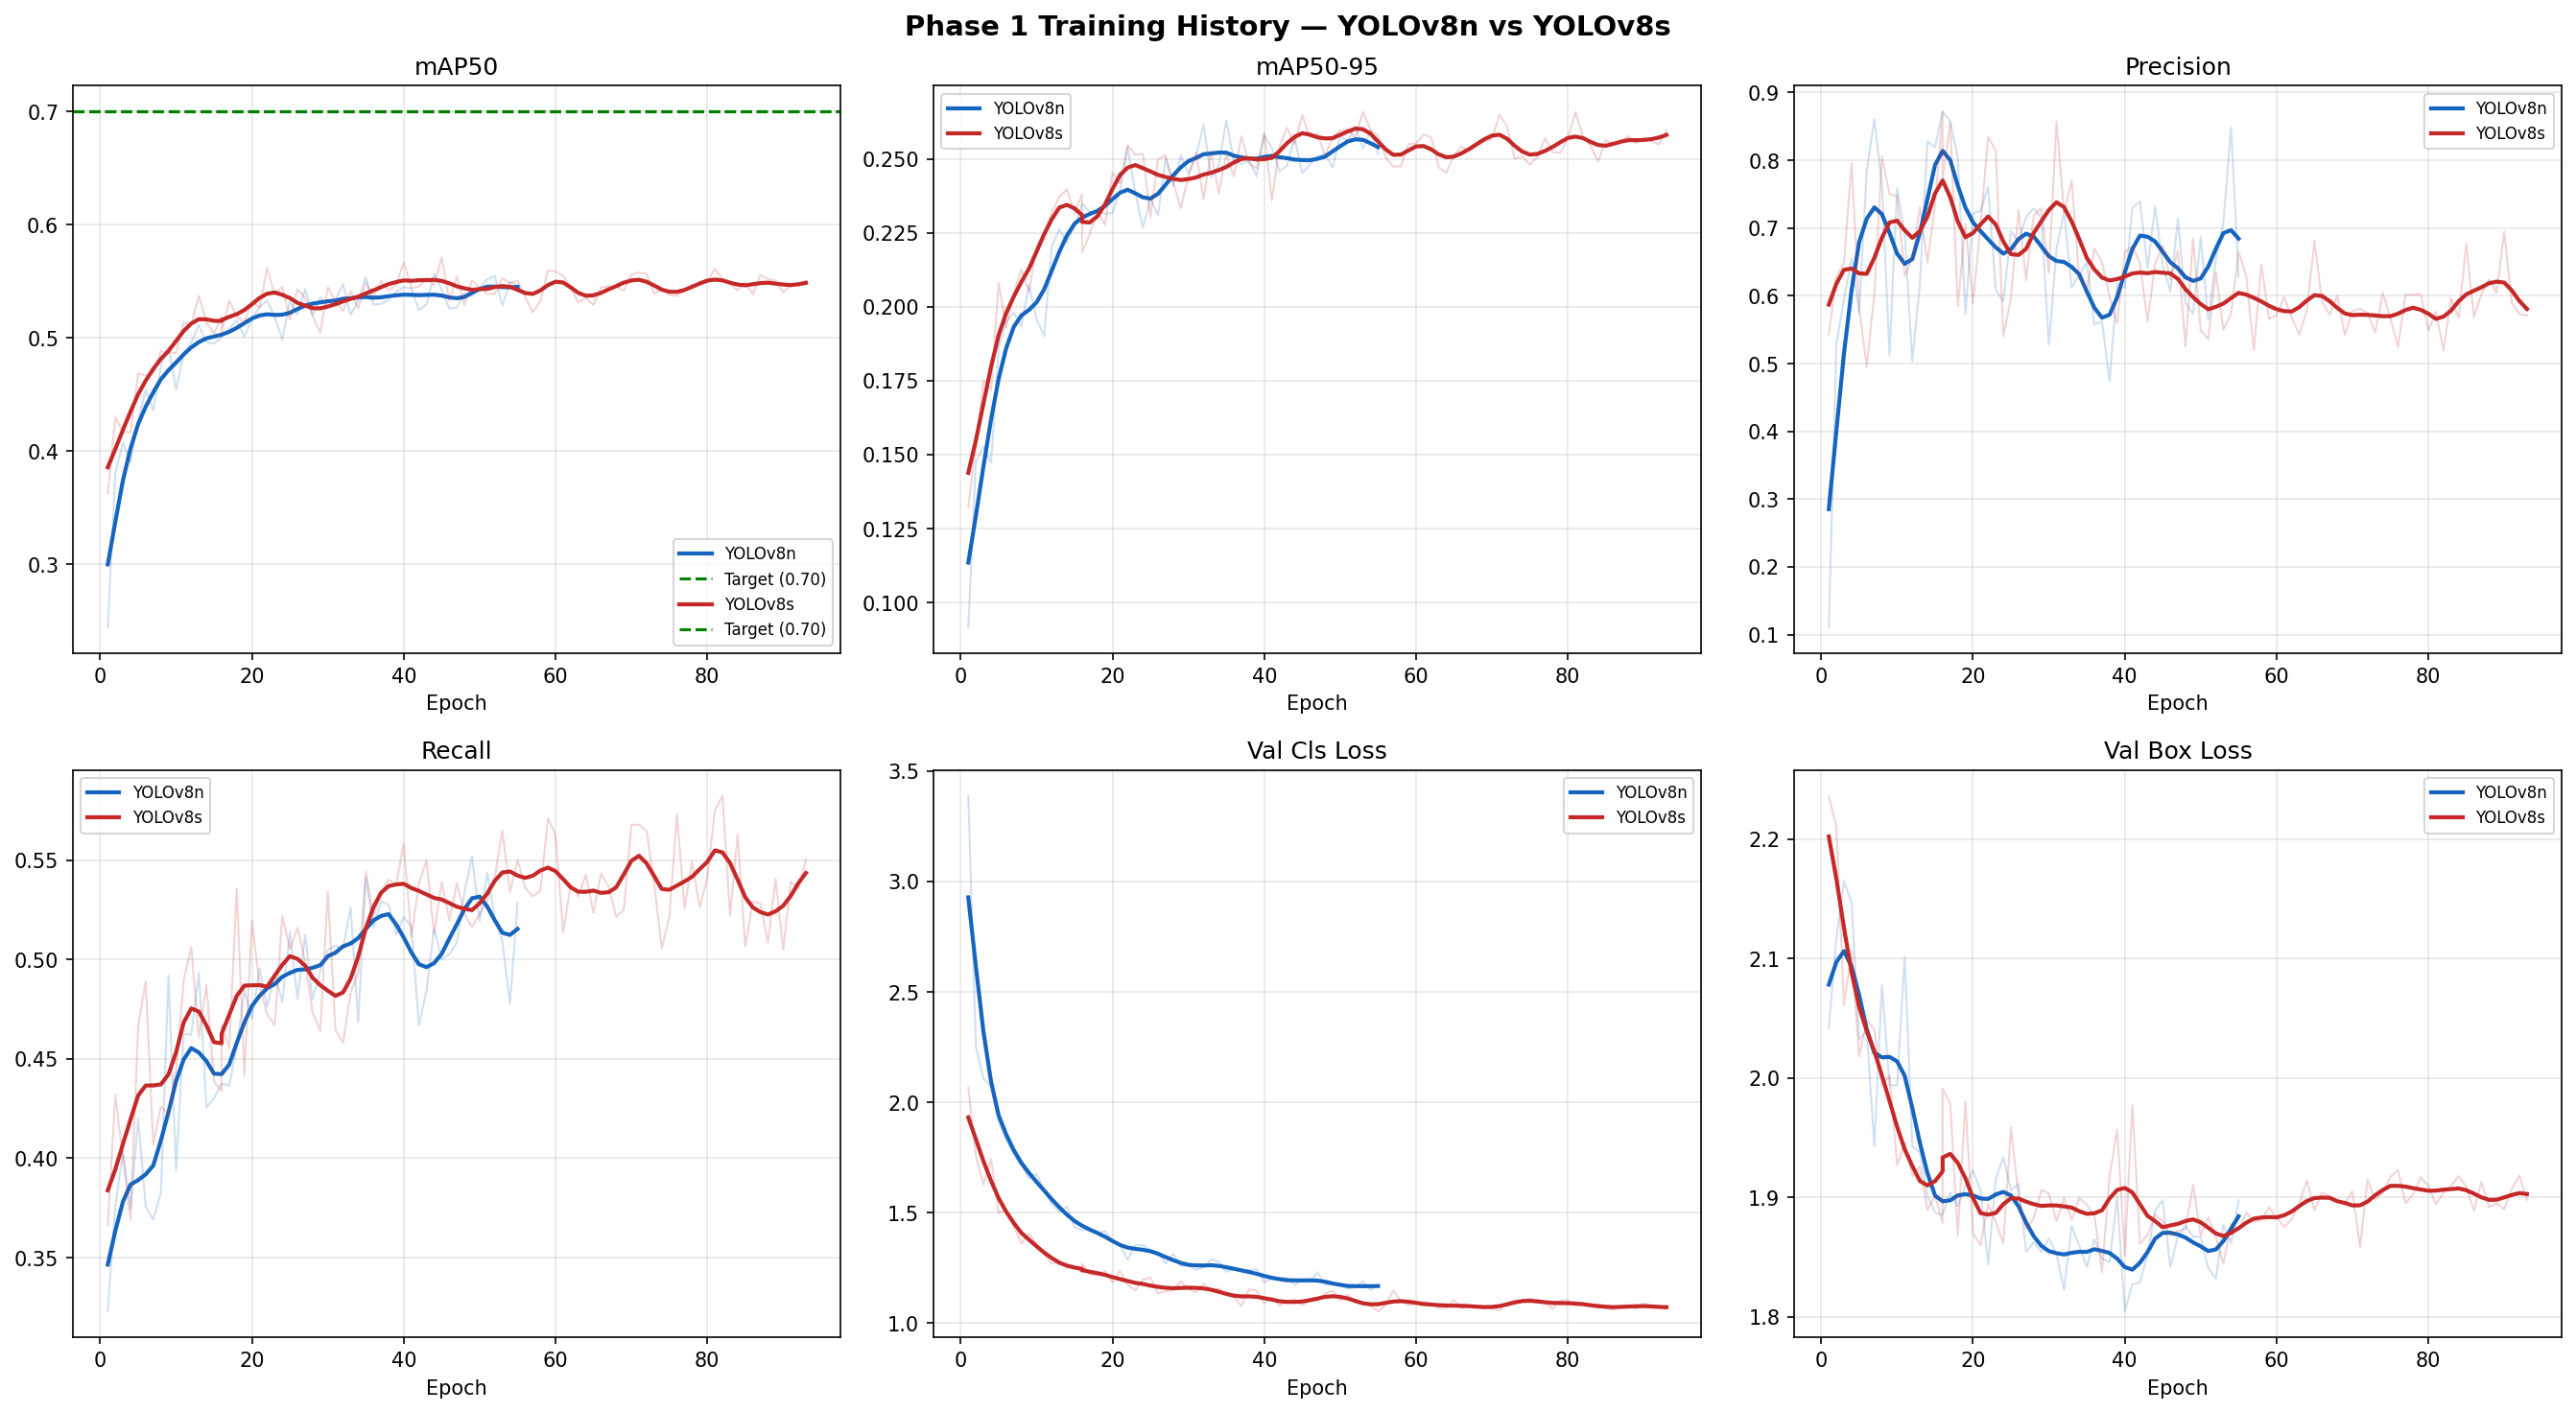

Plot saved to: /content/drive/MyDrive/PPE_Research/phase1/plots/phase1_training_curves.png


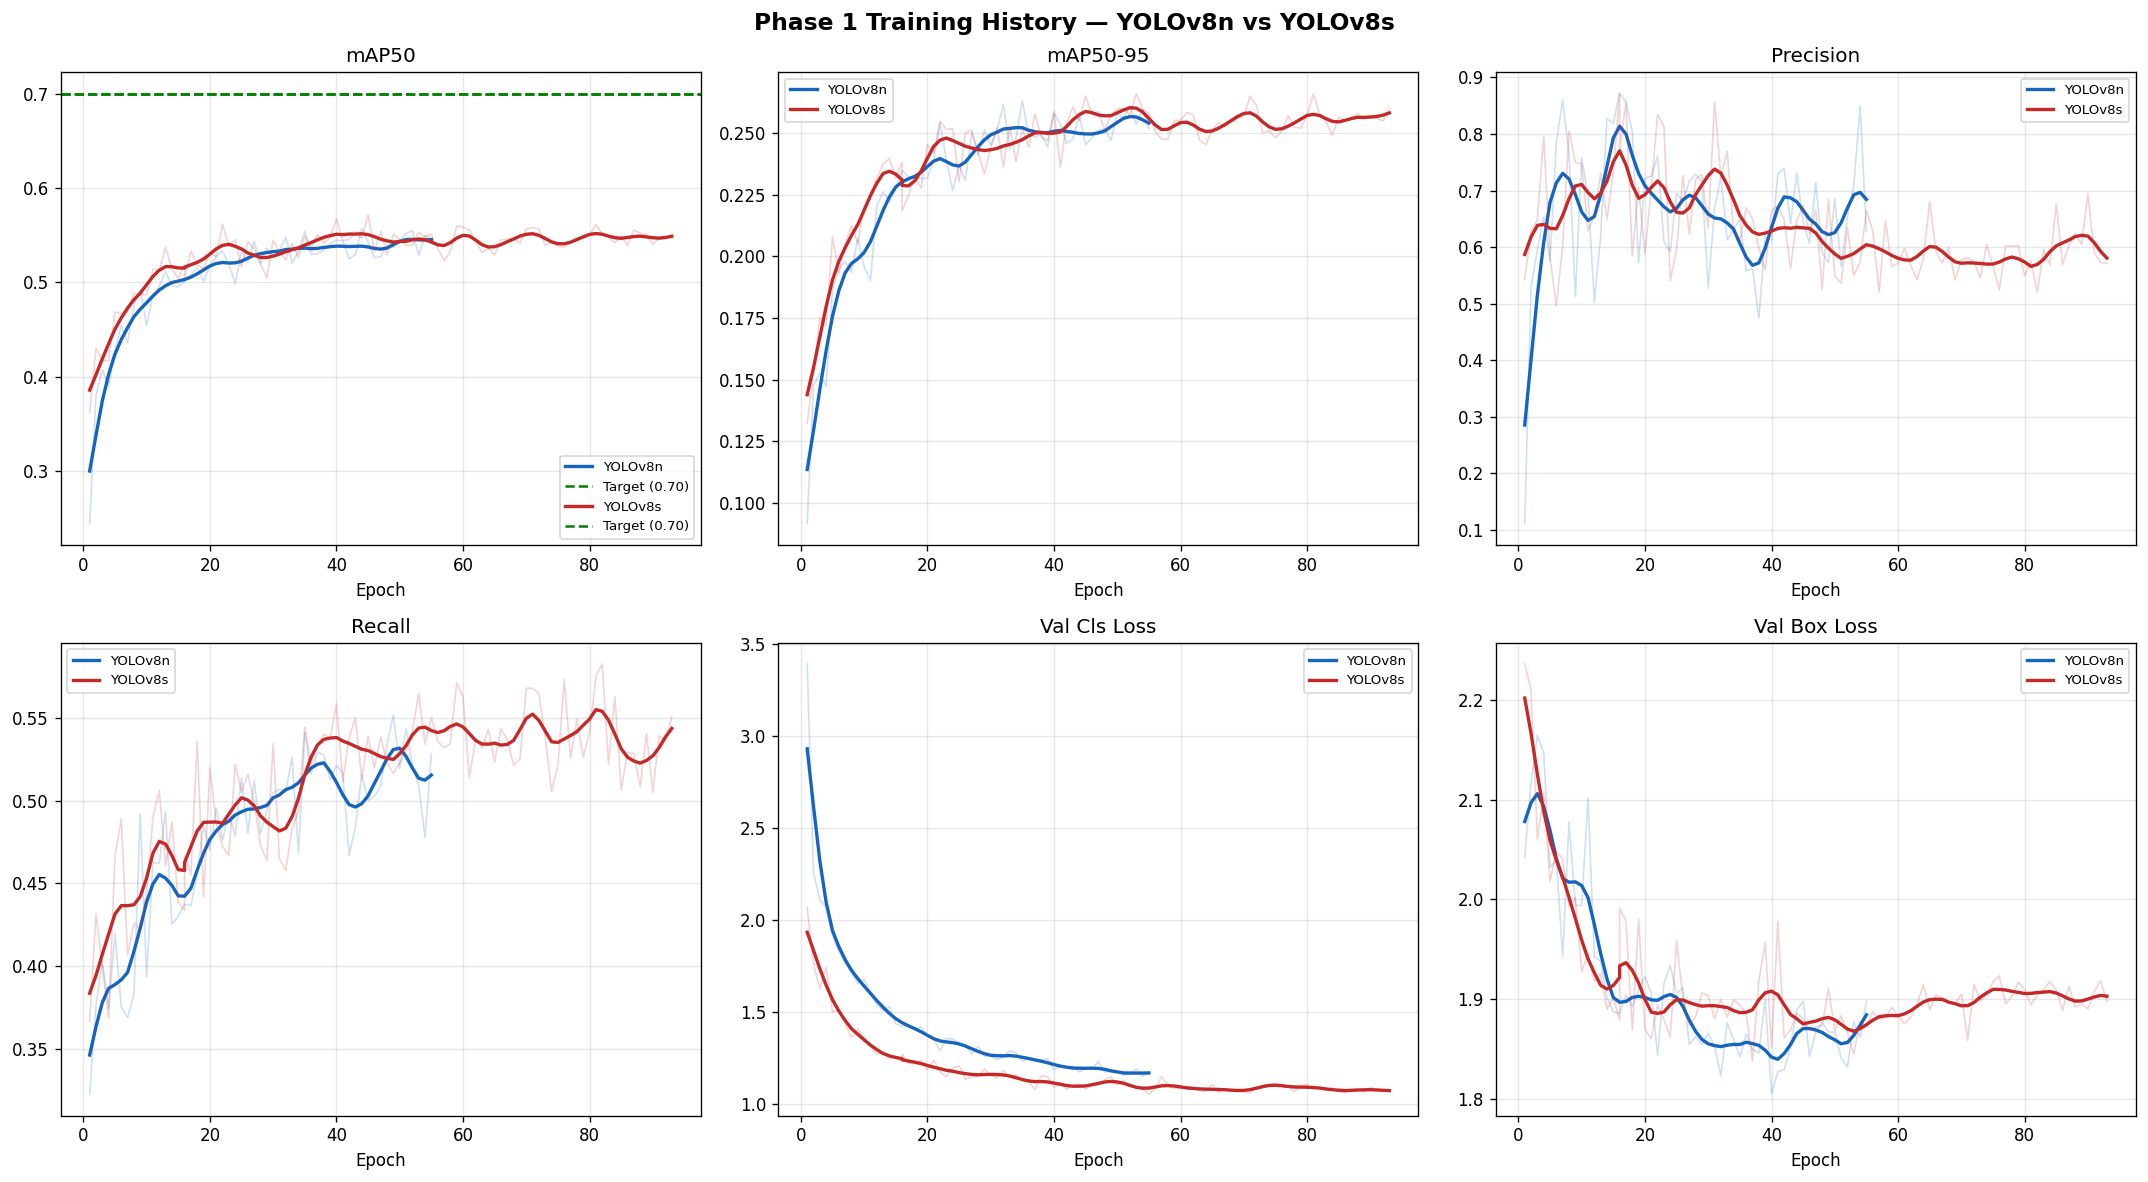

In [9]:
# ============================================================
# CELL 7: Training curves — reads from Drive
# ============================================================
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, os

plt.rcParams.update({'font.size': 10, 'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.3})

def smooth(y, w=7):
    kernel = np.exp(-0.5*((np.arange(w)-w//2)/(w/4))**2)
    kernel /= kernel.sum()
    return np.convolve(np.pad(y,w//2,mode='edge'), kernel, mode='valid')

def load_results(run_dir):
    csv = f'{run_dir}/results.csv'
    if not os.path.exists(csv): return None
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()
    return df

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Phase 1 Training History — YOLOv8n vs YOLOv8s', fontsize=14, fontweight='bold')

colors  = ['#1565C0', '#C62828']
names   = ['YOLOv8n', 'YOLOv8s']
dirs    = [EXP1_DRIVE_DIR, EXP2_DRIVE_DIR]
metrics = [
    ('metrics/mAP50(B)',     'mAP50',       axes[0,0], True),
    ('metrics/mAP50-95(B)', 'mAP50-95',    axes[0,1], False),
    ('metrics/precision(B)', 'Precision',   axes[0,2], False),
    ('metrics/recall(B)',   'Recall',       axes[1,0], False),
    ('val/cls_loss',        'Val Cls Loss', axes[1,1], False),
    ('val/box_loss',        'Val Box Loss', axes[1,2], False),
]

any_data = False
for run_dir, label, color in zip(dirs, names, colors):
    df = load_results(run_dir)
    if df is None: continue
    any_data = True
    ep = df['epoch'].values
    for col, title, ax, add_target in metrics:
        if col in df.columns:
            vals = df[col].values
            ax.plot(ep, vals, color=color, alpha=0.2, linewidth=1)
            ax.plot(ep, smooth(vals), color=color, linewidth=2, label=label)
            ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(fontsize=8)
            if add_target:
                ax.axhline(0.70, color='green', linestyle='--', linewidth=1.5, label='Target (0.70)')
                ax.legend(fontsize=8)

if not any_data:
    print('No results.csv found. Run Cells 4 and 5 first.')

plt.tight_layout()
plot_path = f'{DRIVE_PLOTS_DIR}/phase1_training_curves.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
display(Image(filename=plot_path, width=1100))
print(f'Plot saved to: {plot_path}')

---
## Cell 8 — Display All Training Artifact Plots


 Exp1 YOLOv8n
--- Training History (Loss + mAP) ---


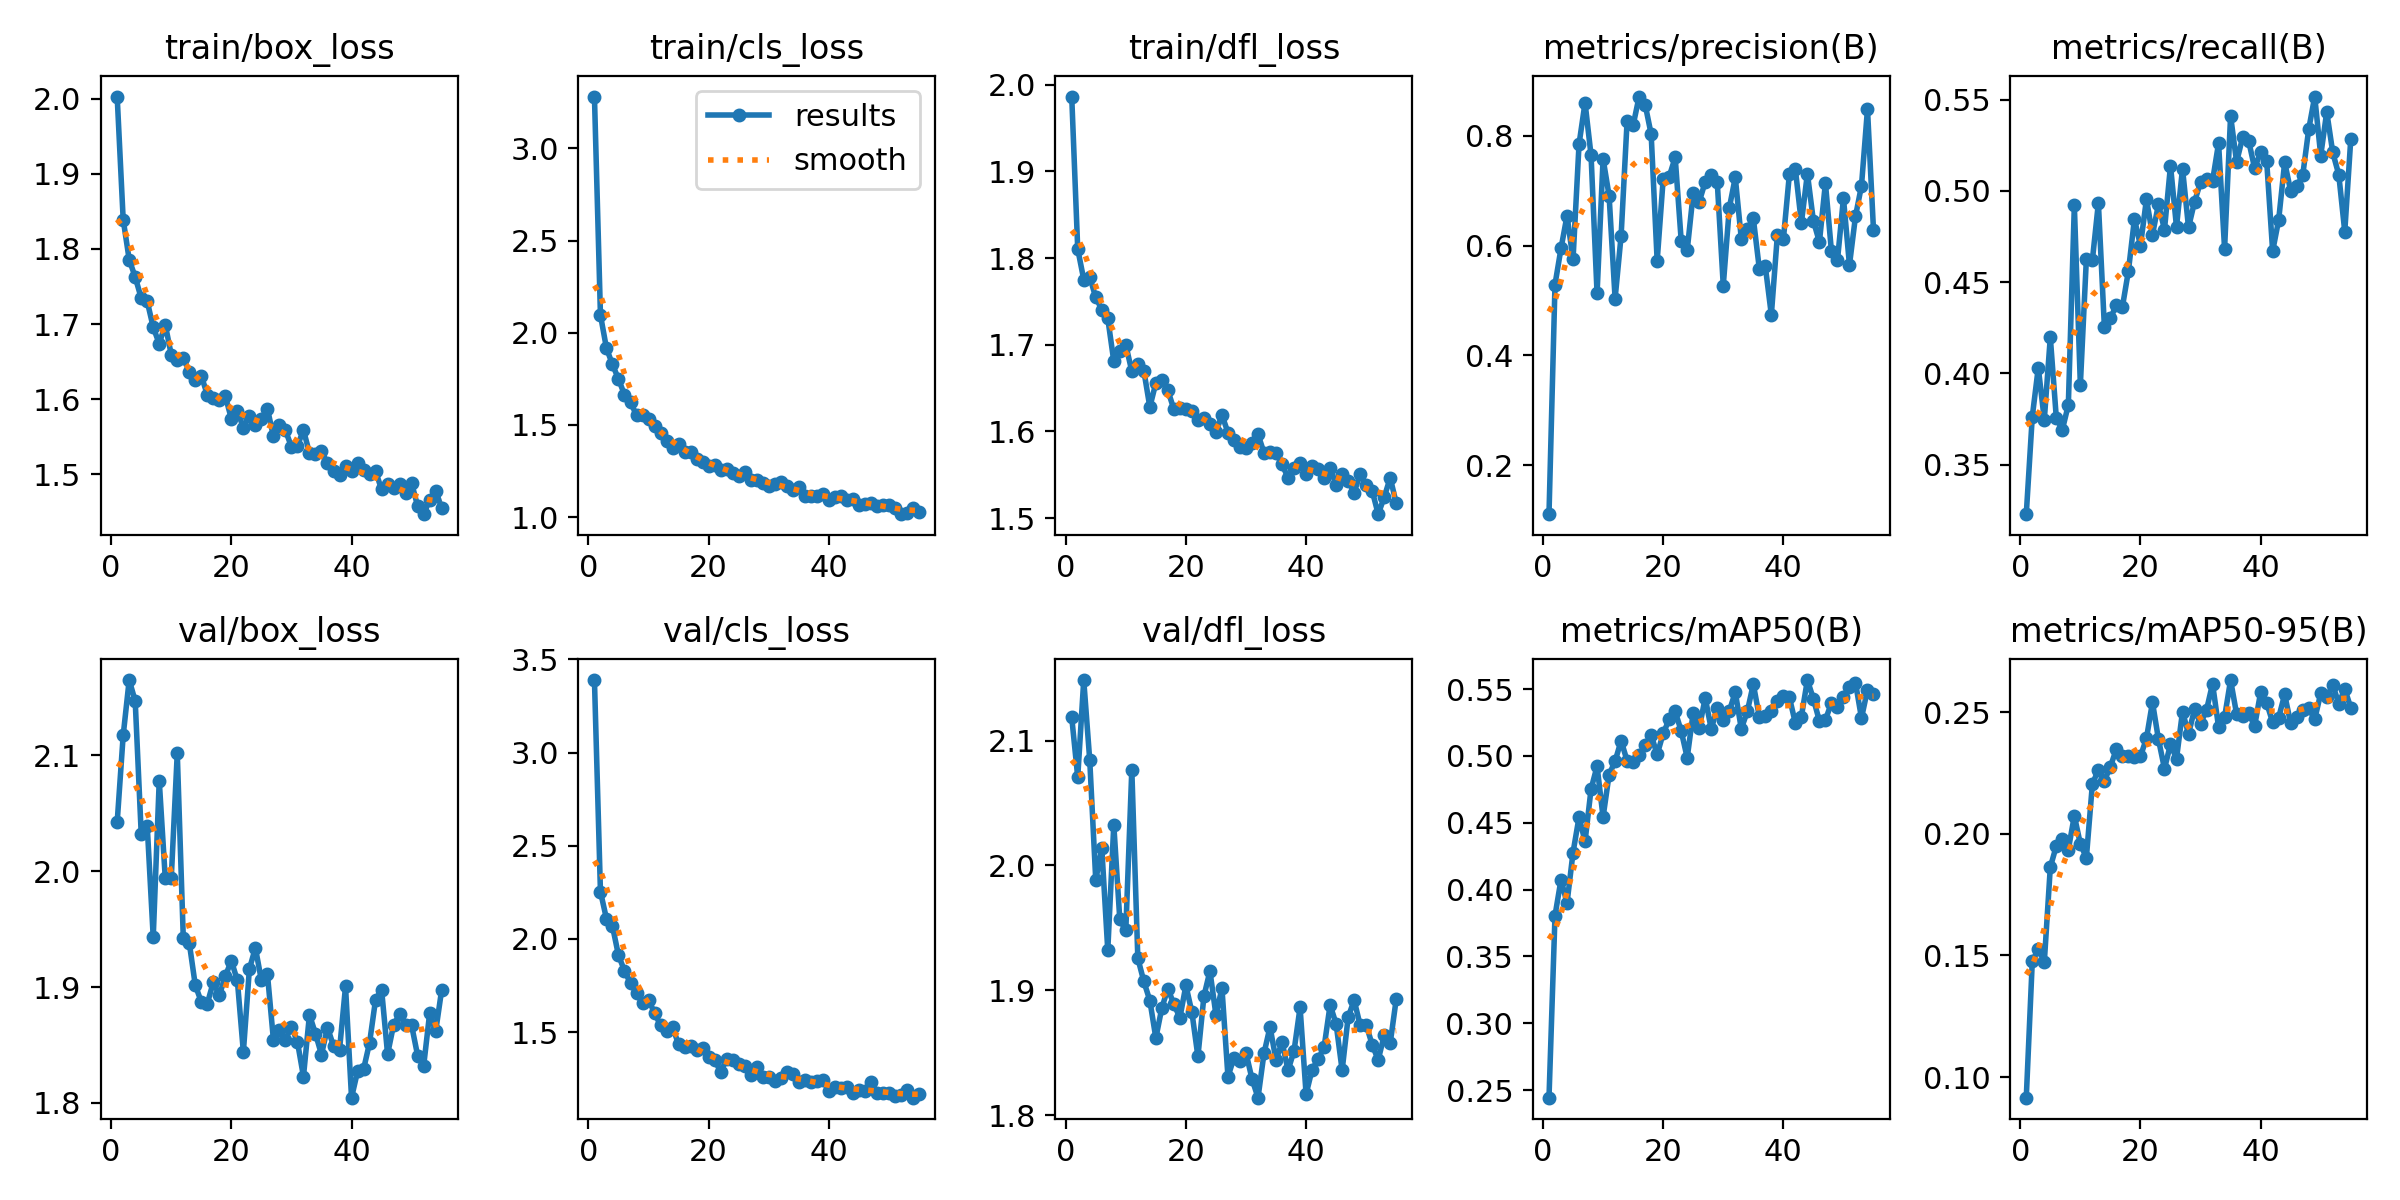

--- Confusion Matrix ---


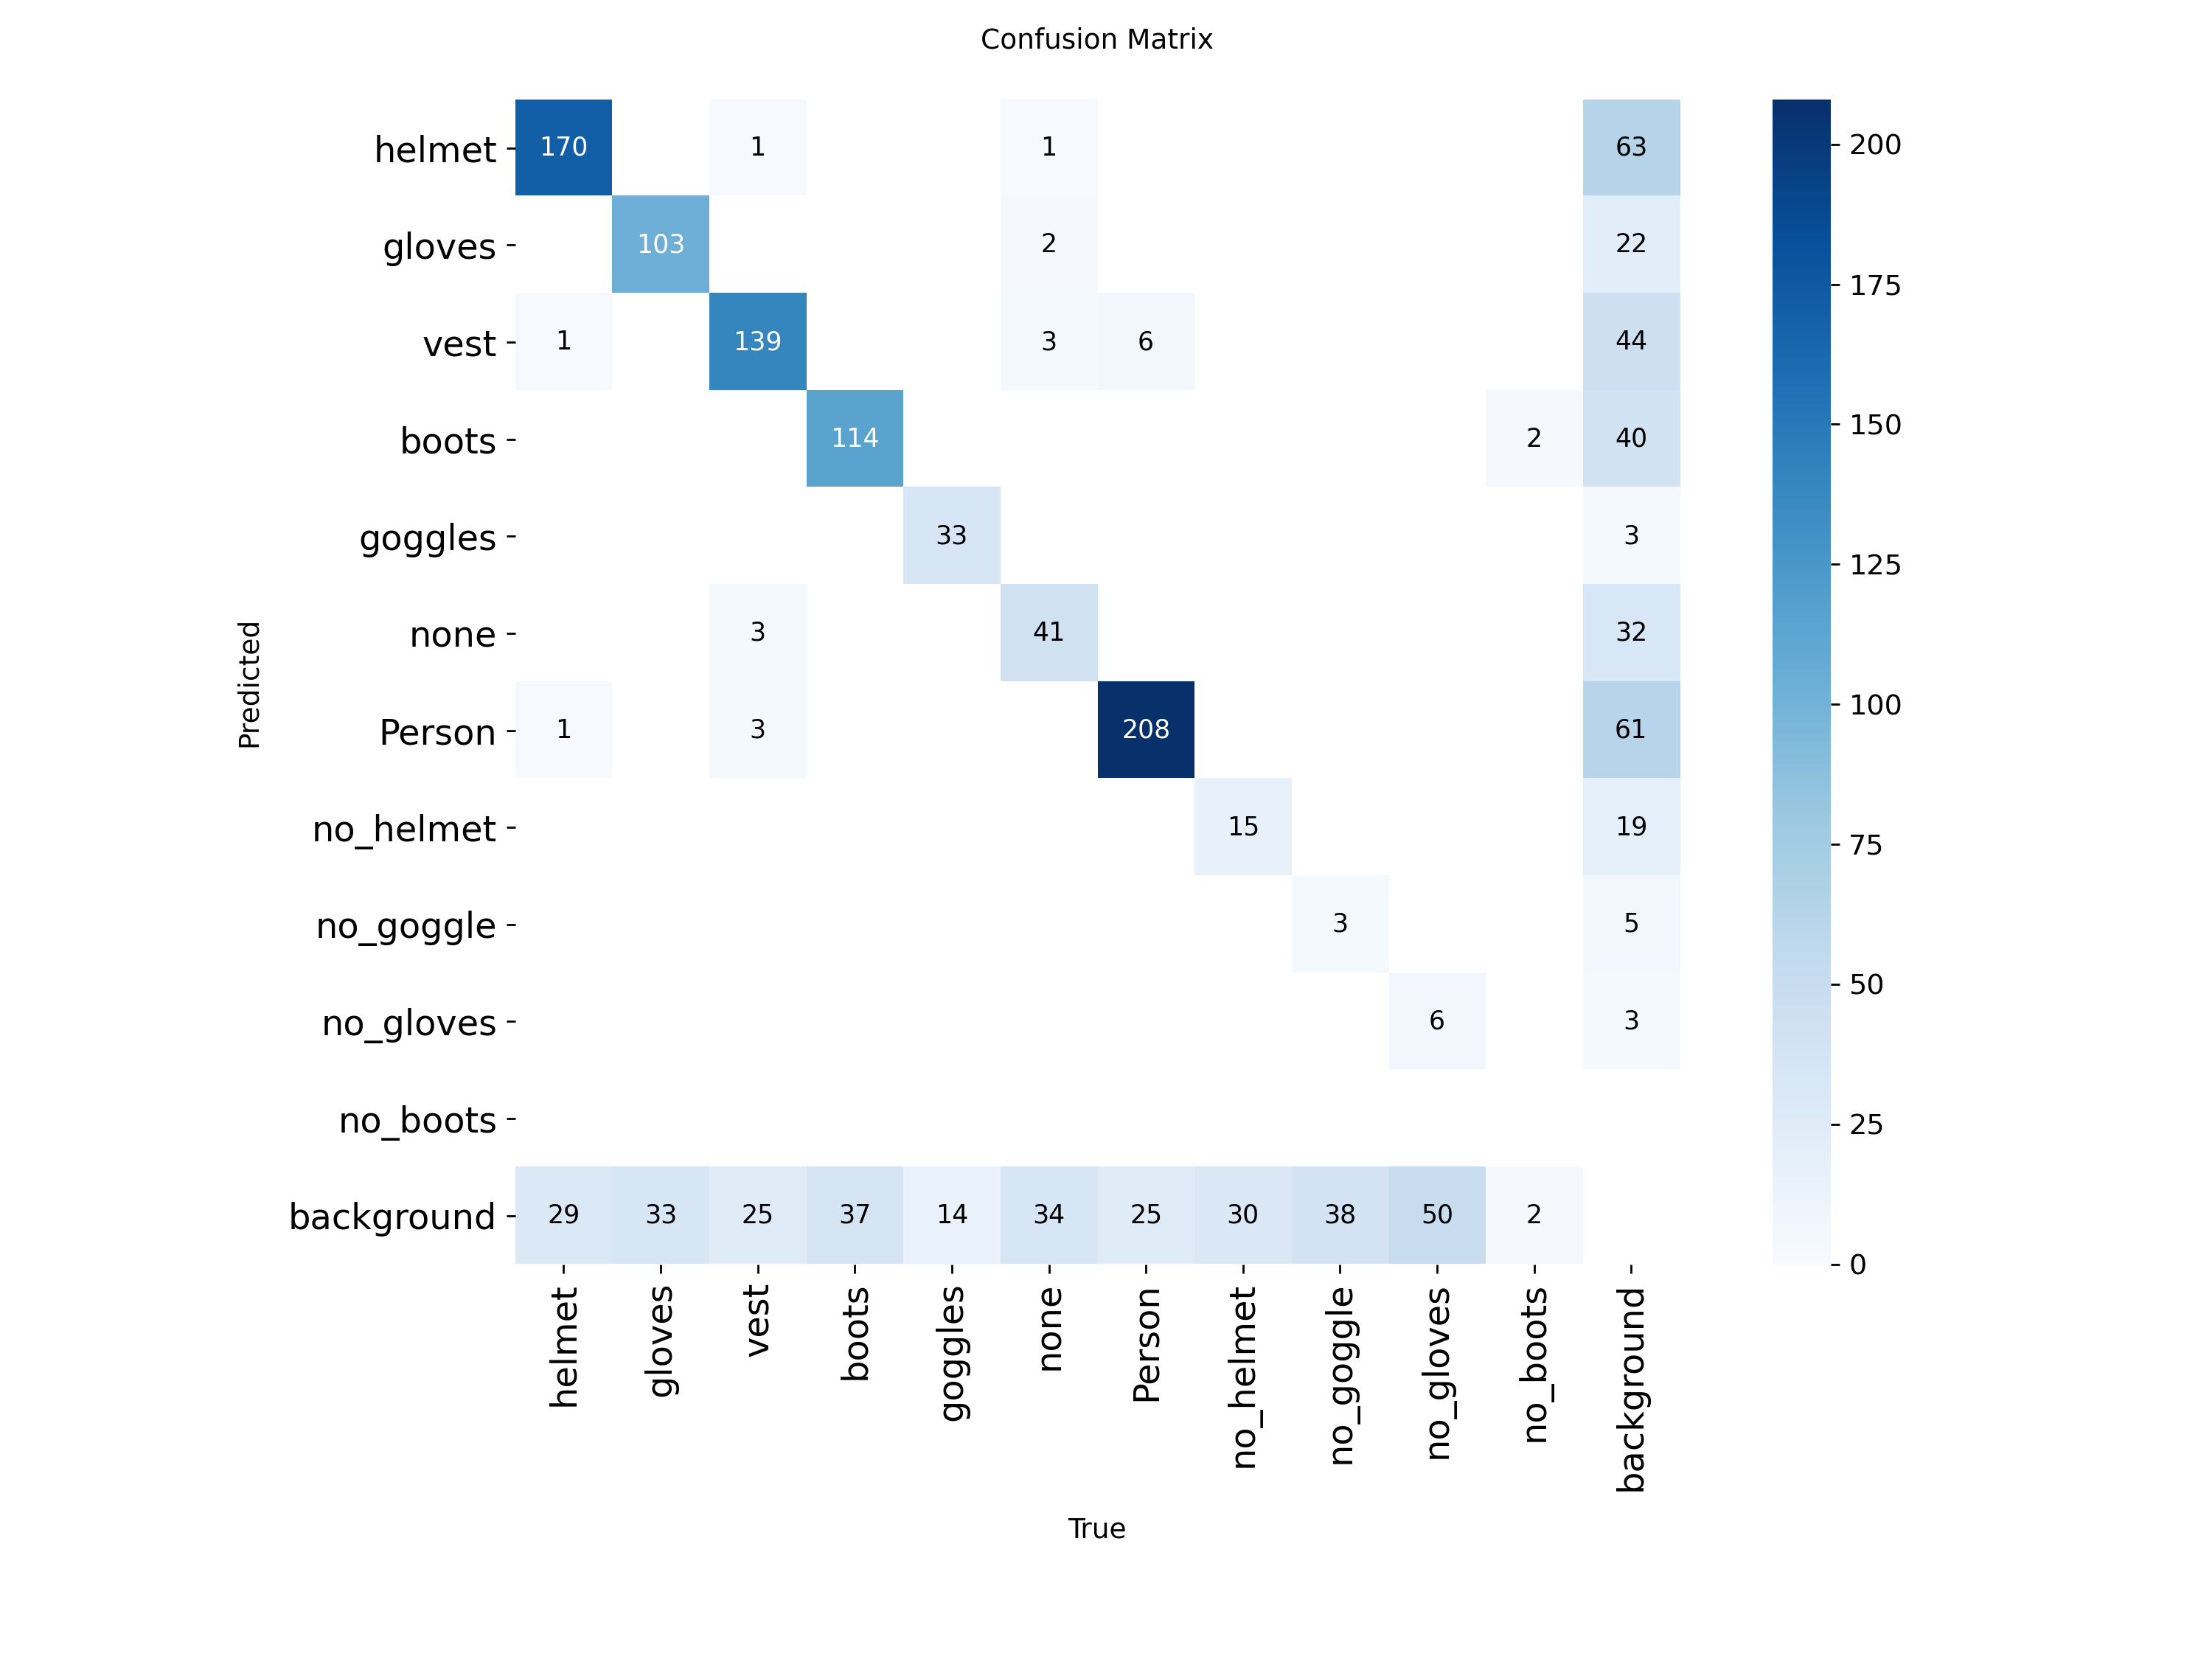

--- Confusion Matrix (Normalized) ---


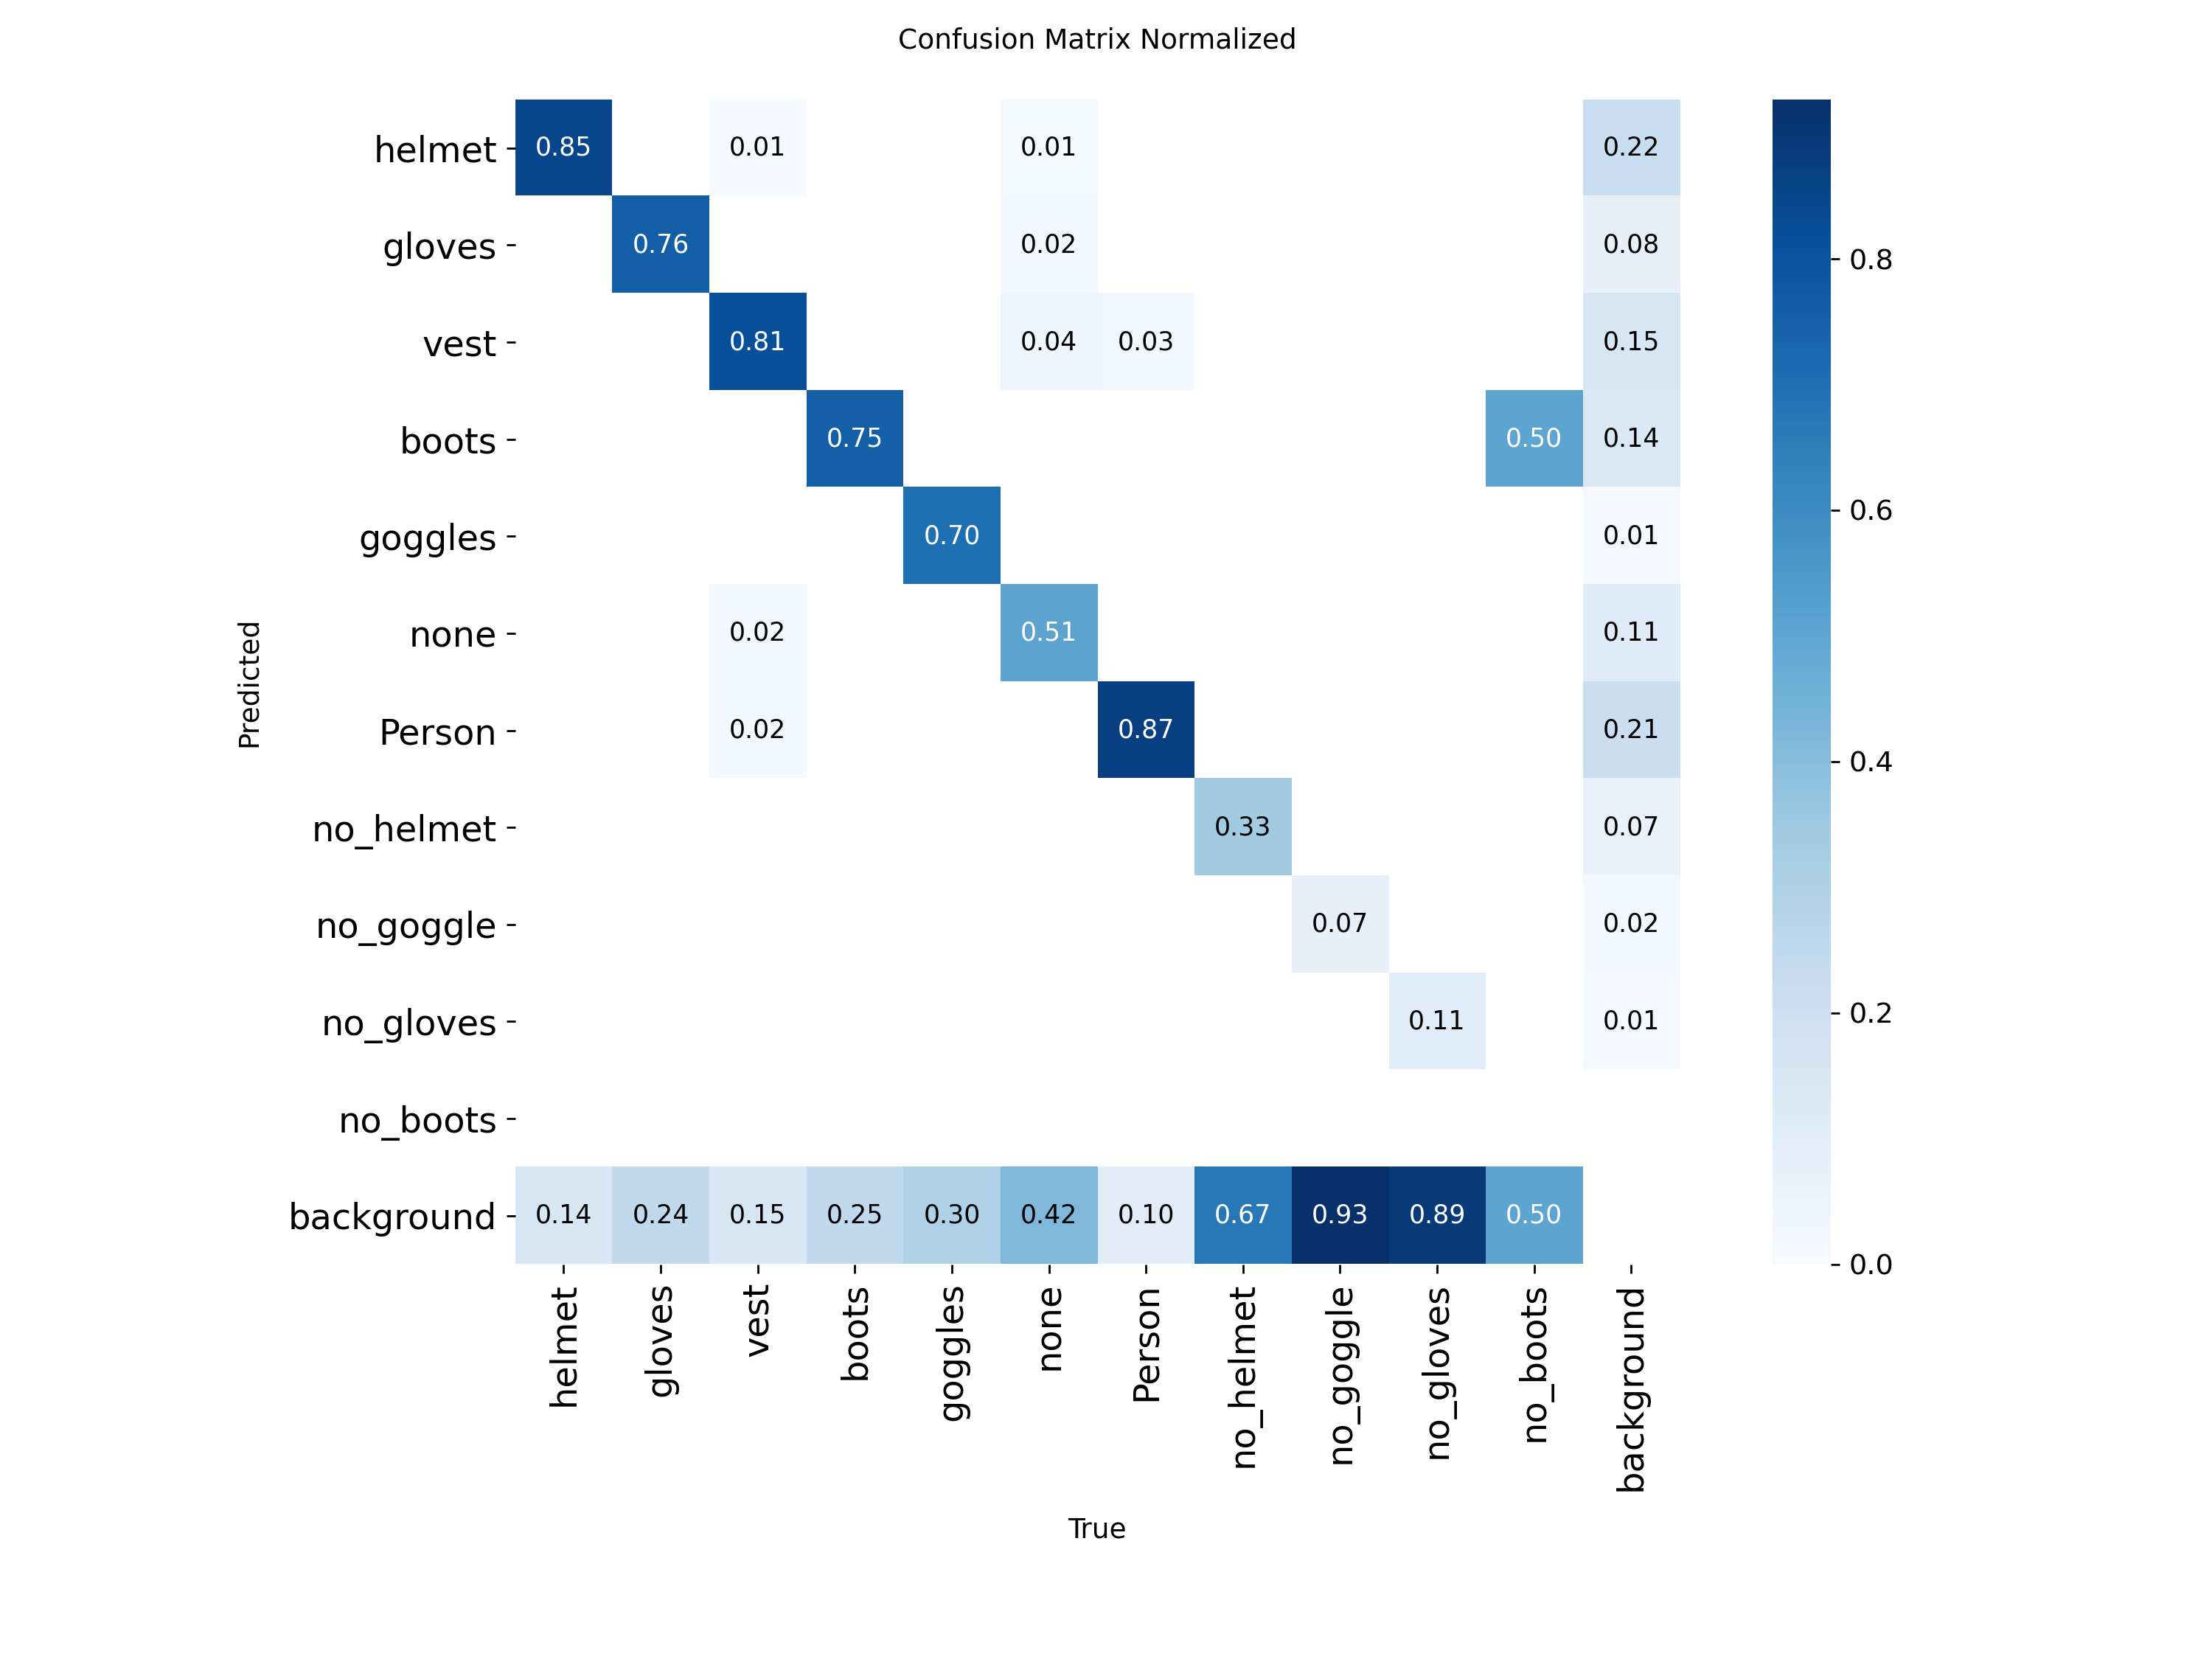

  [PR_curve.png] not yet available.
  [F1_curve.png] not yet available.
--- Validation Batch Predictions ---


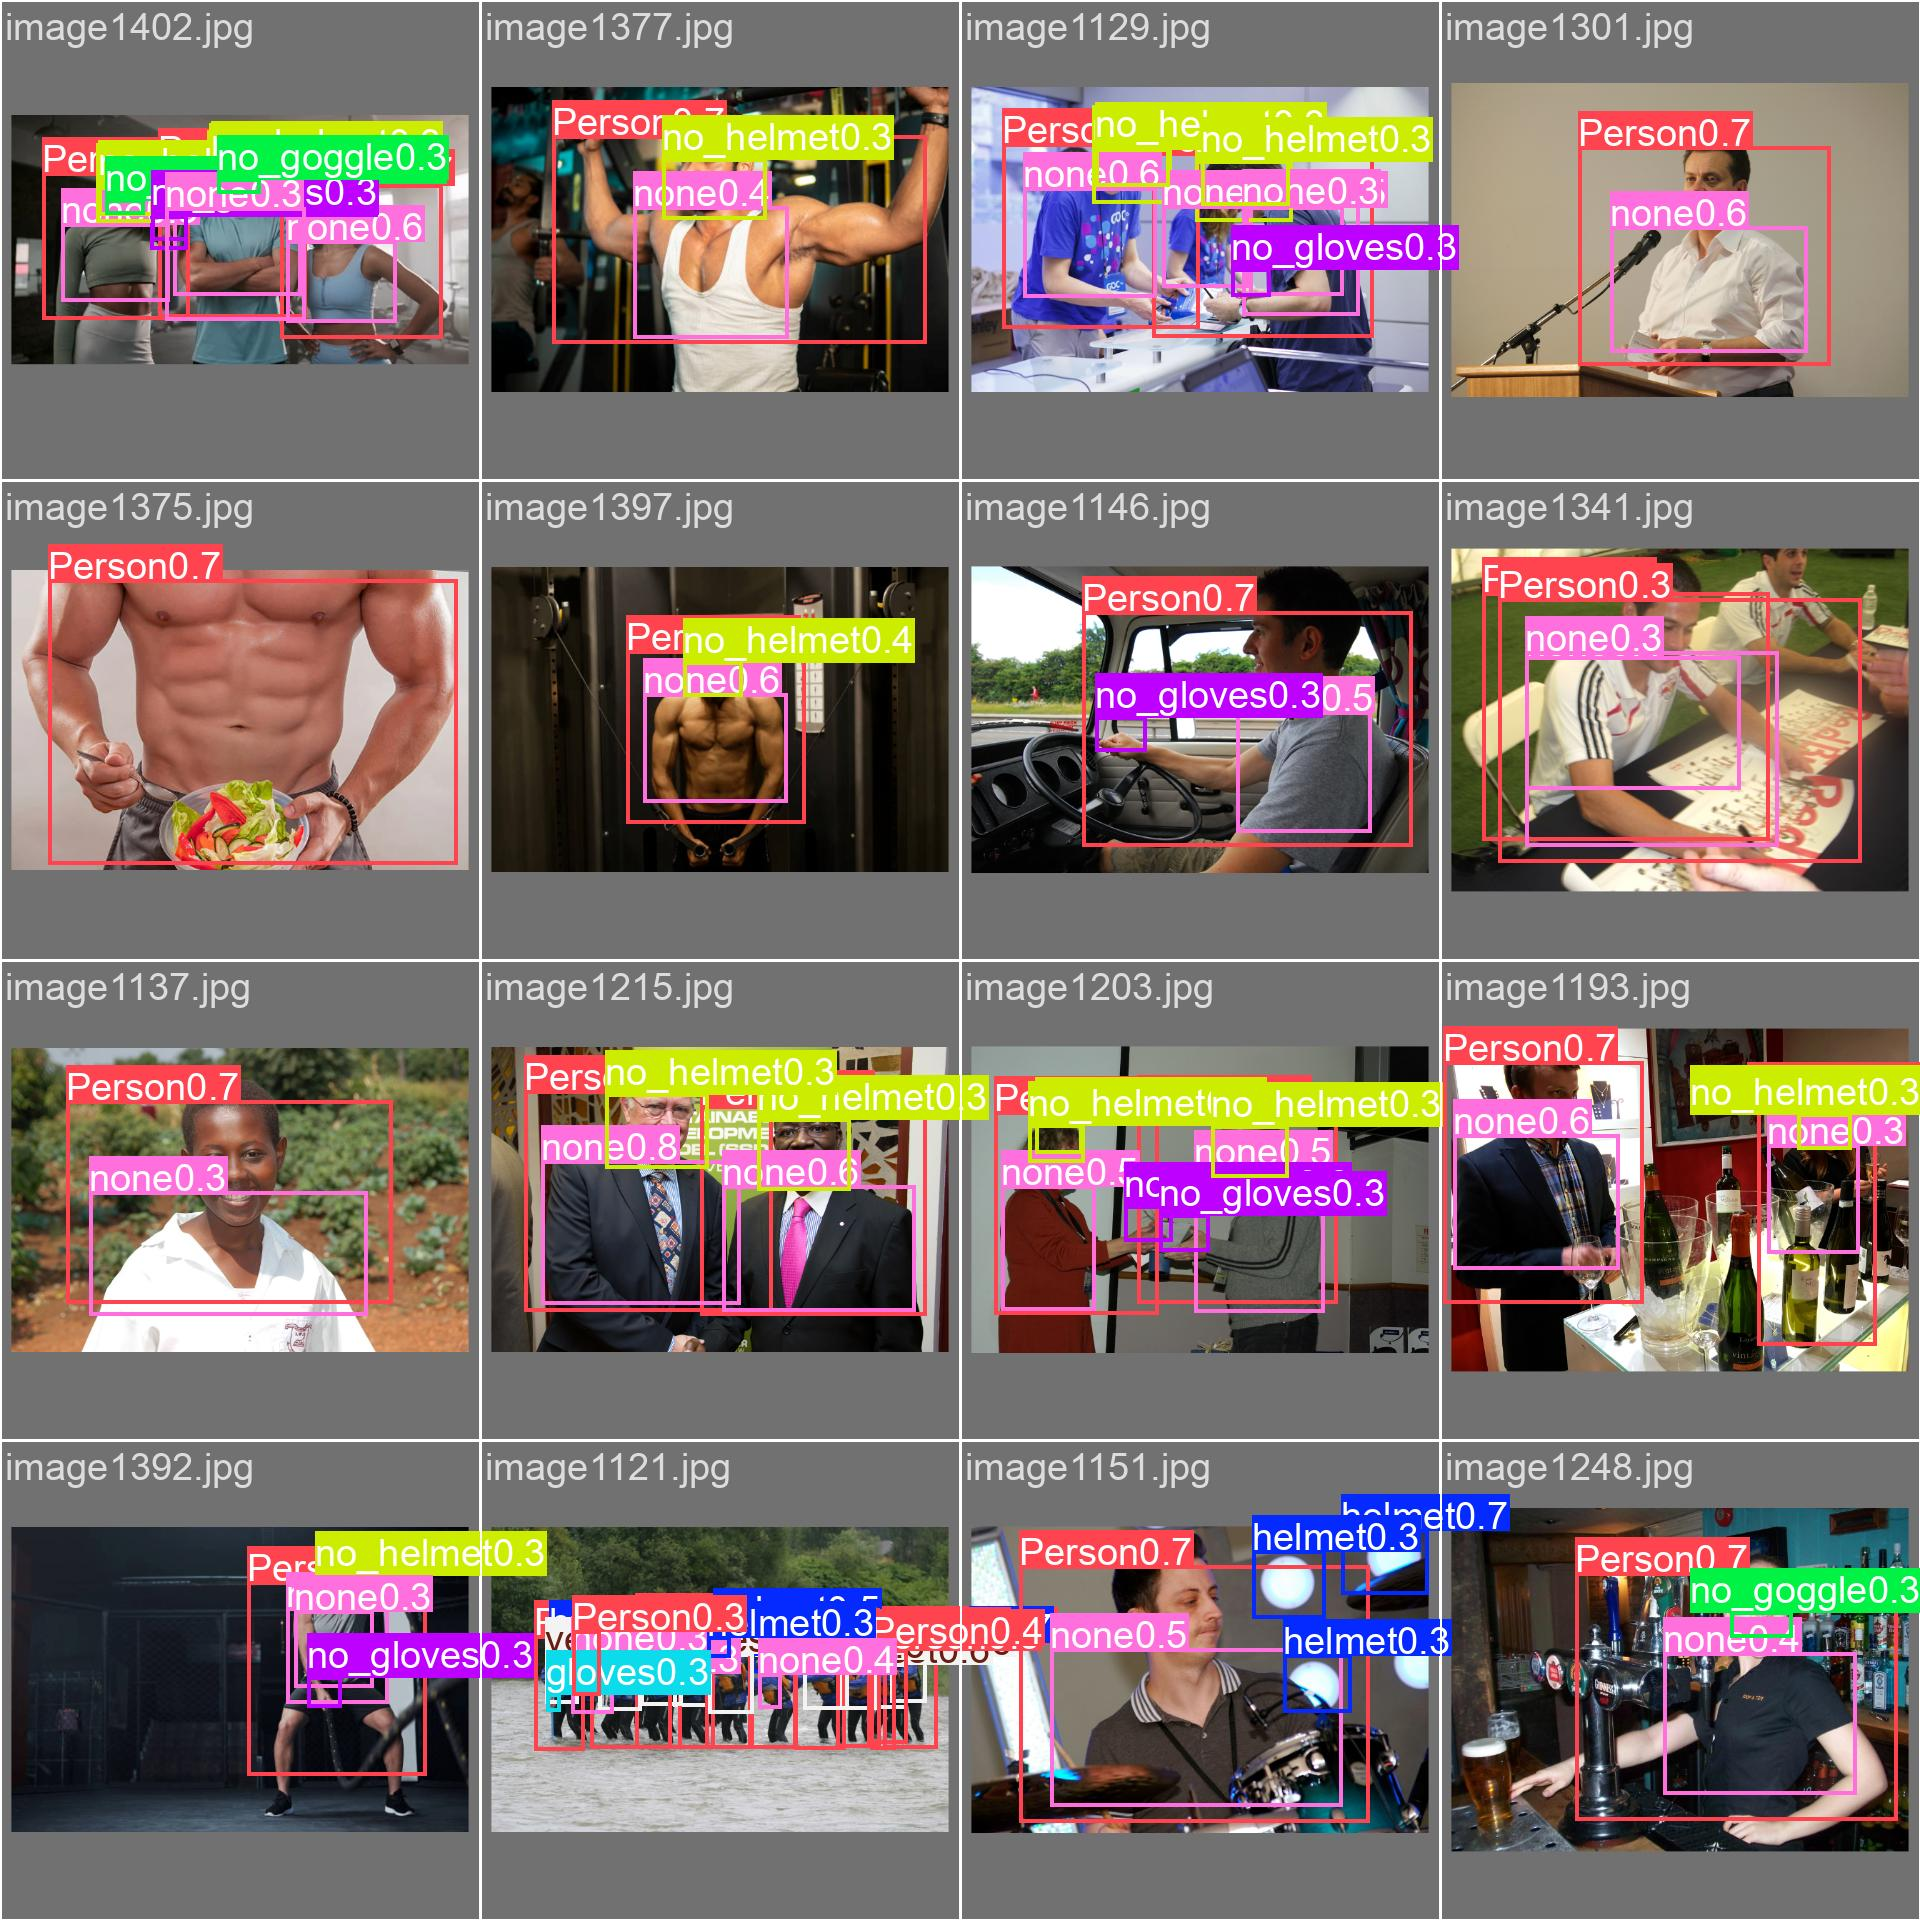

--- Validation Ground Truth ---


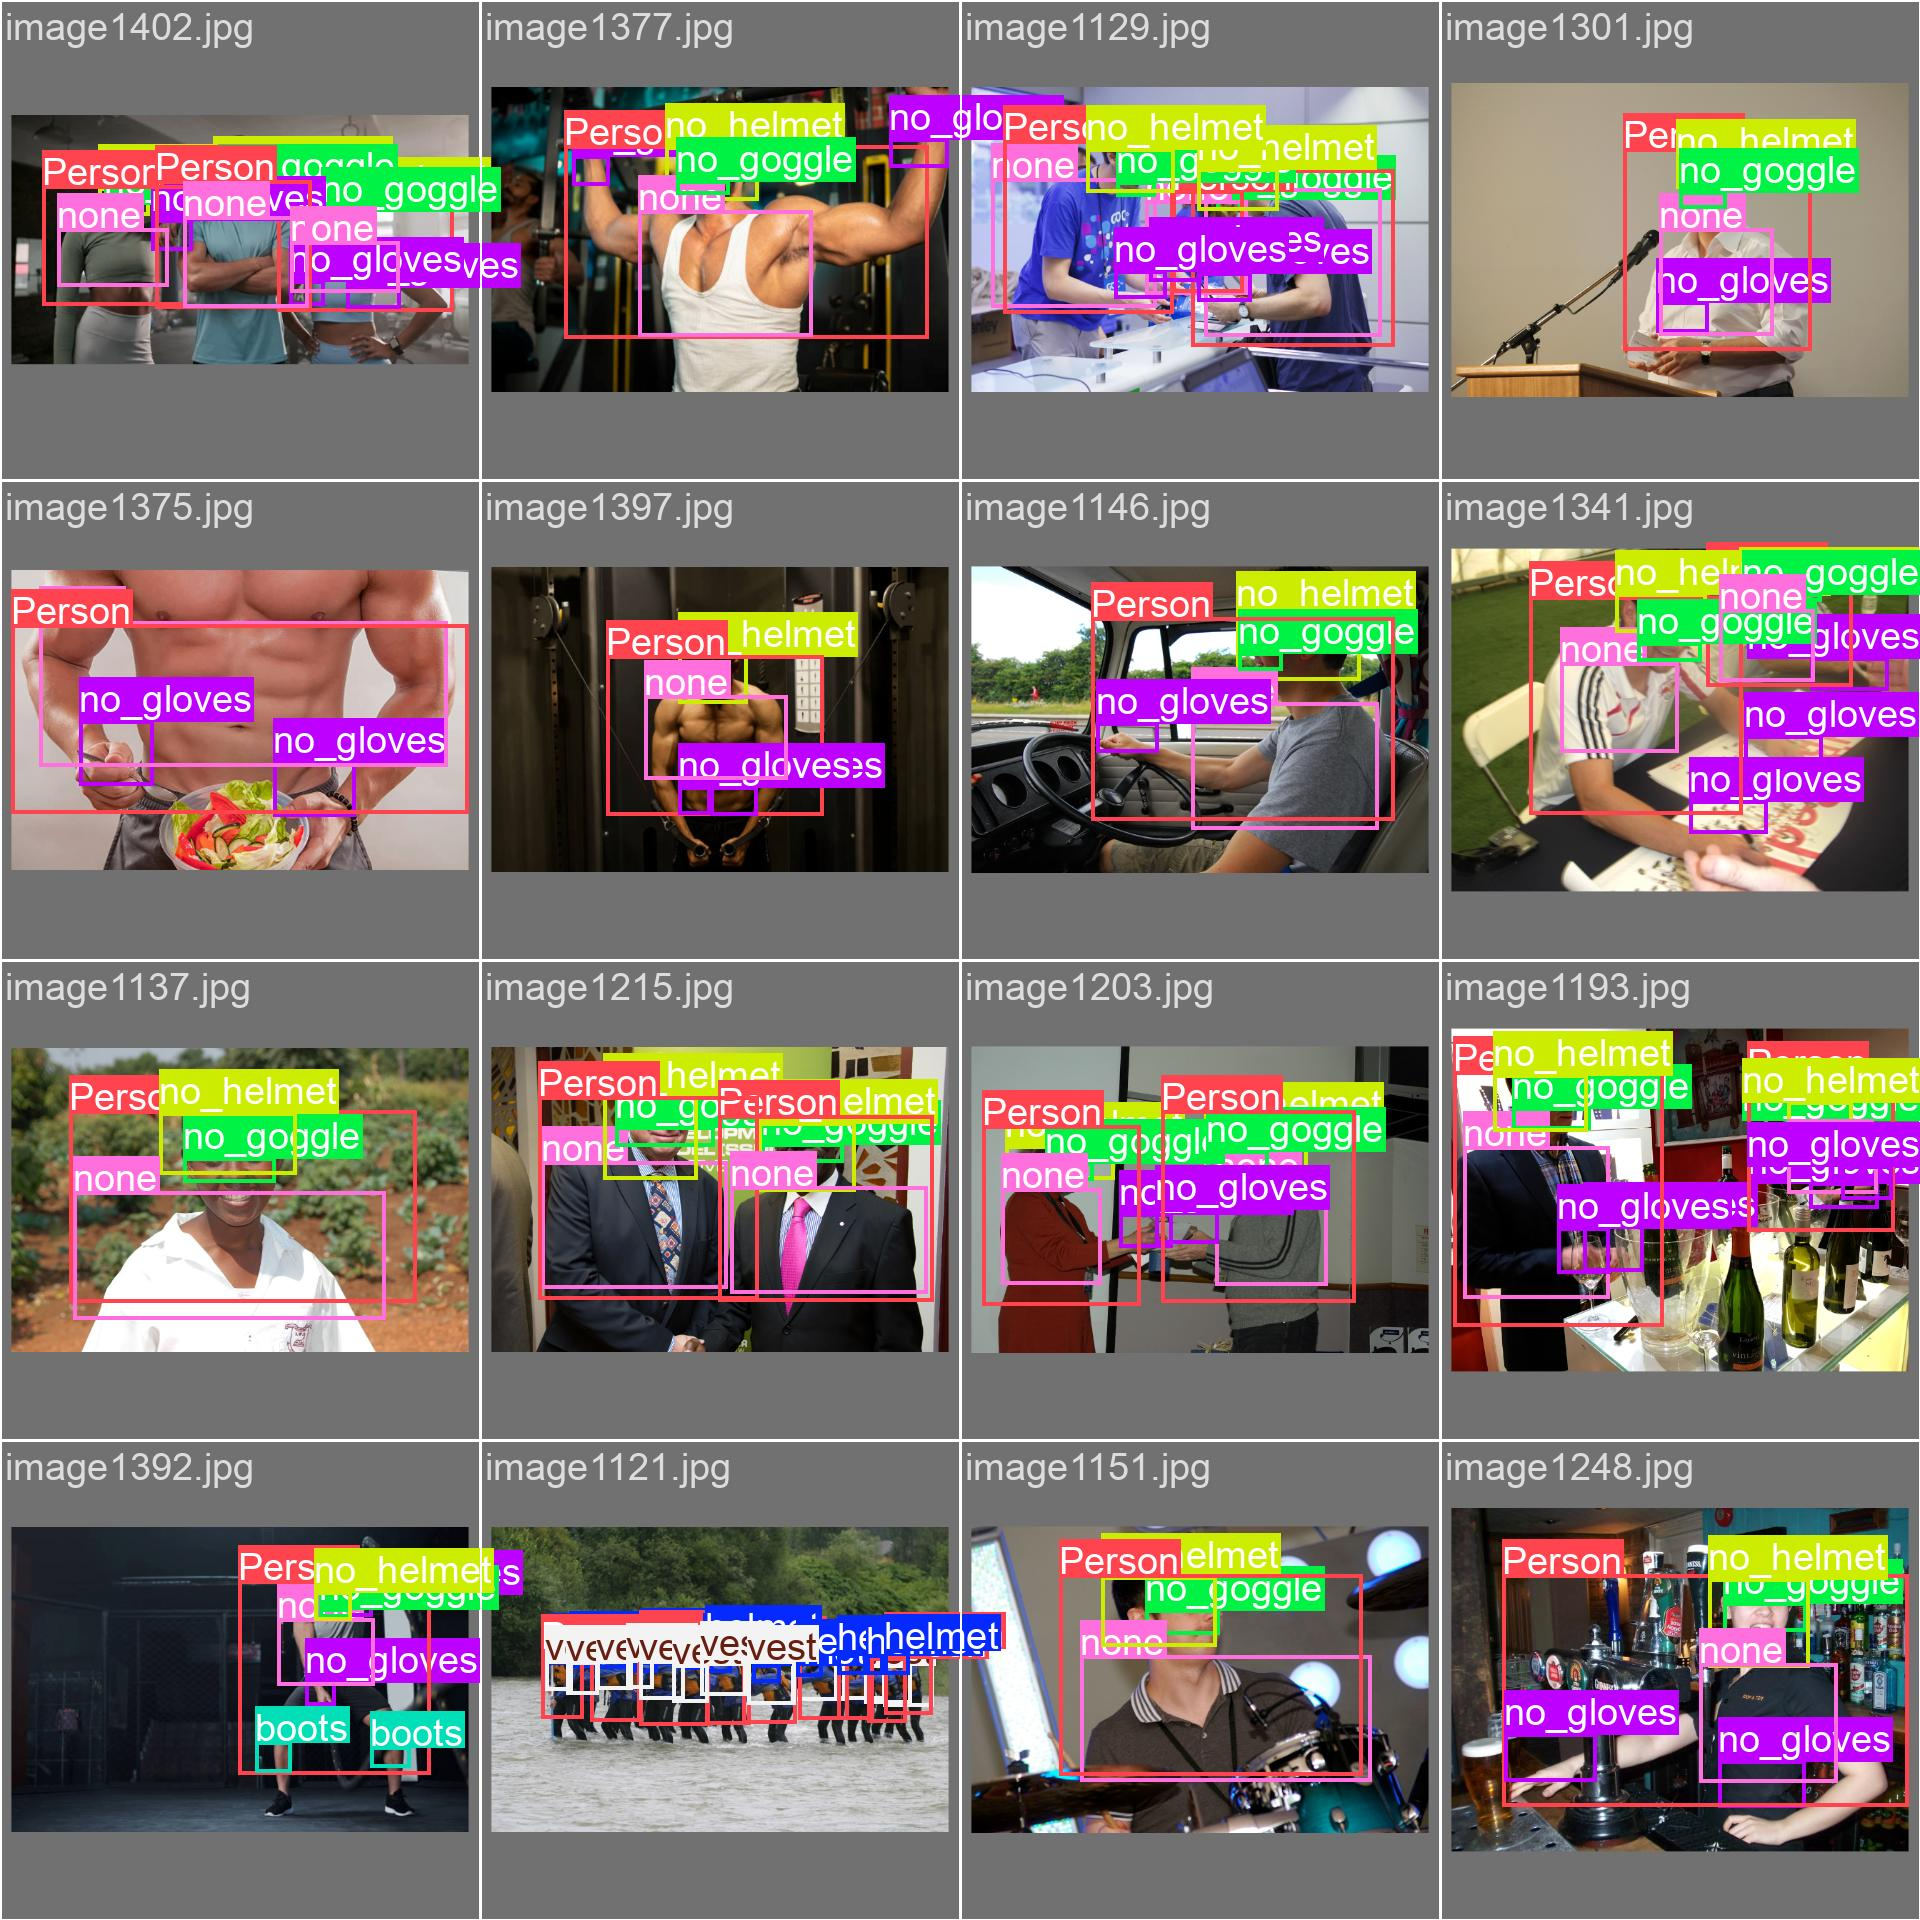


 Exp2 YOLOv8s
--- Training History (Loss + mAP) ---


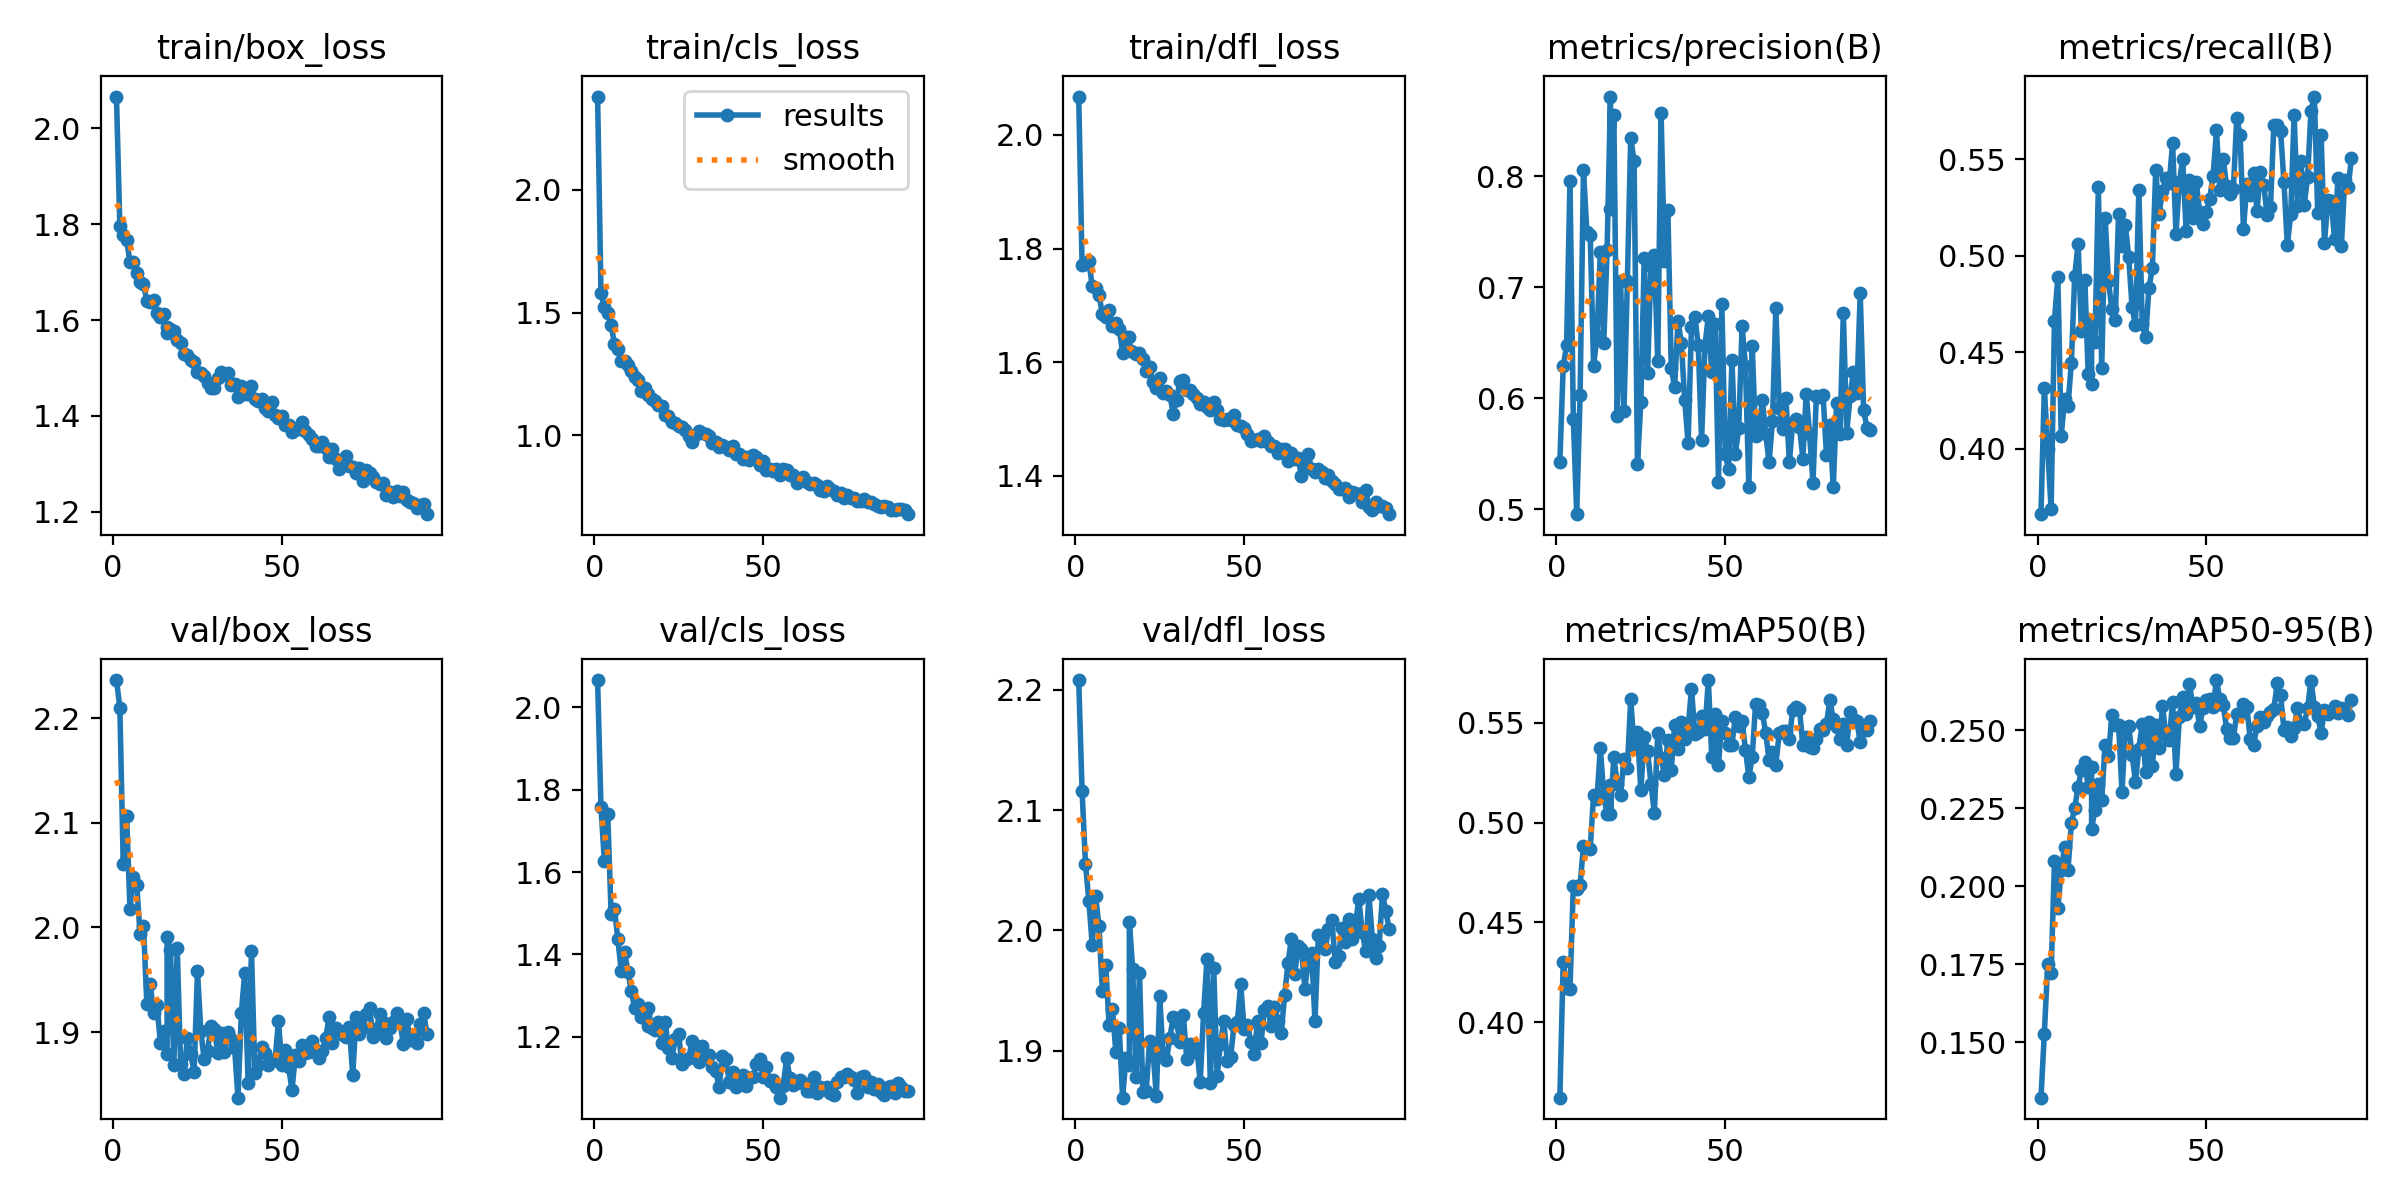

--- Confusion Matrix ---


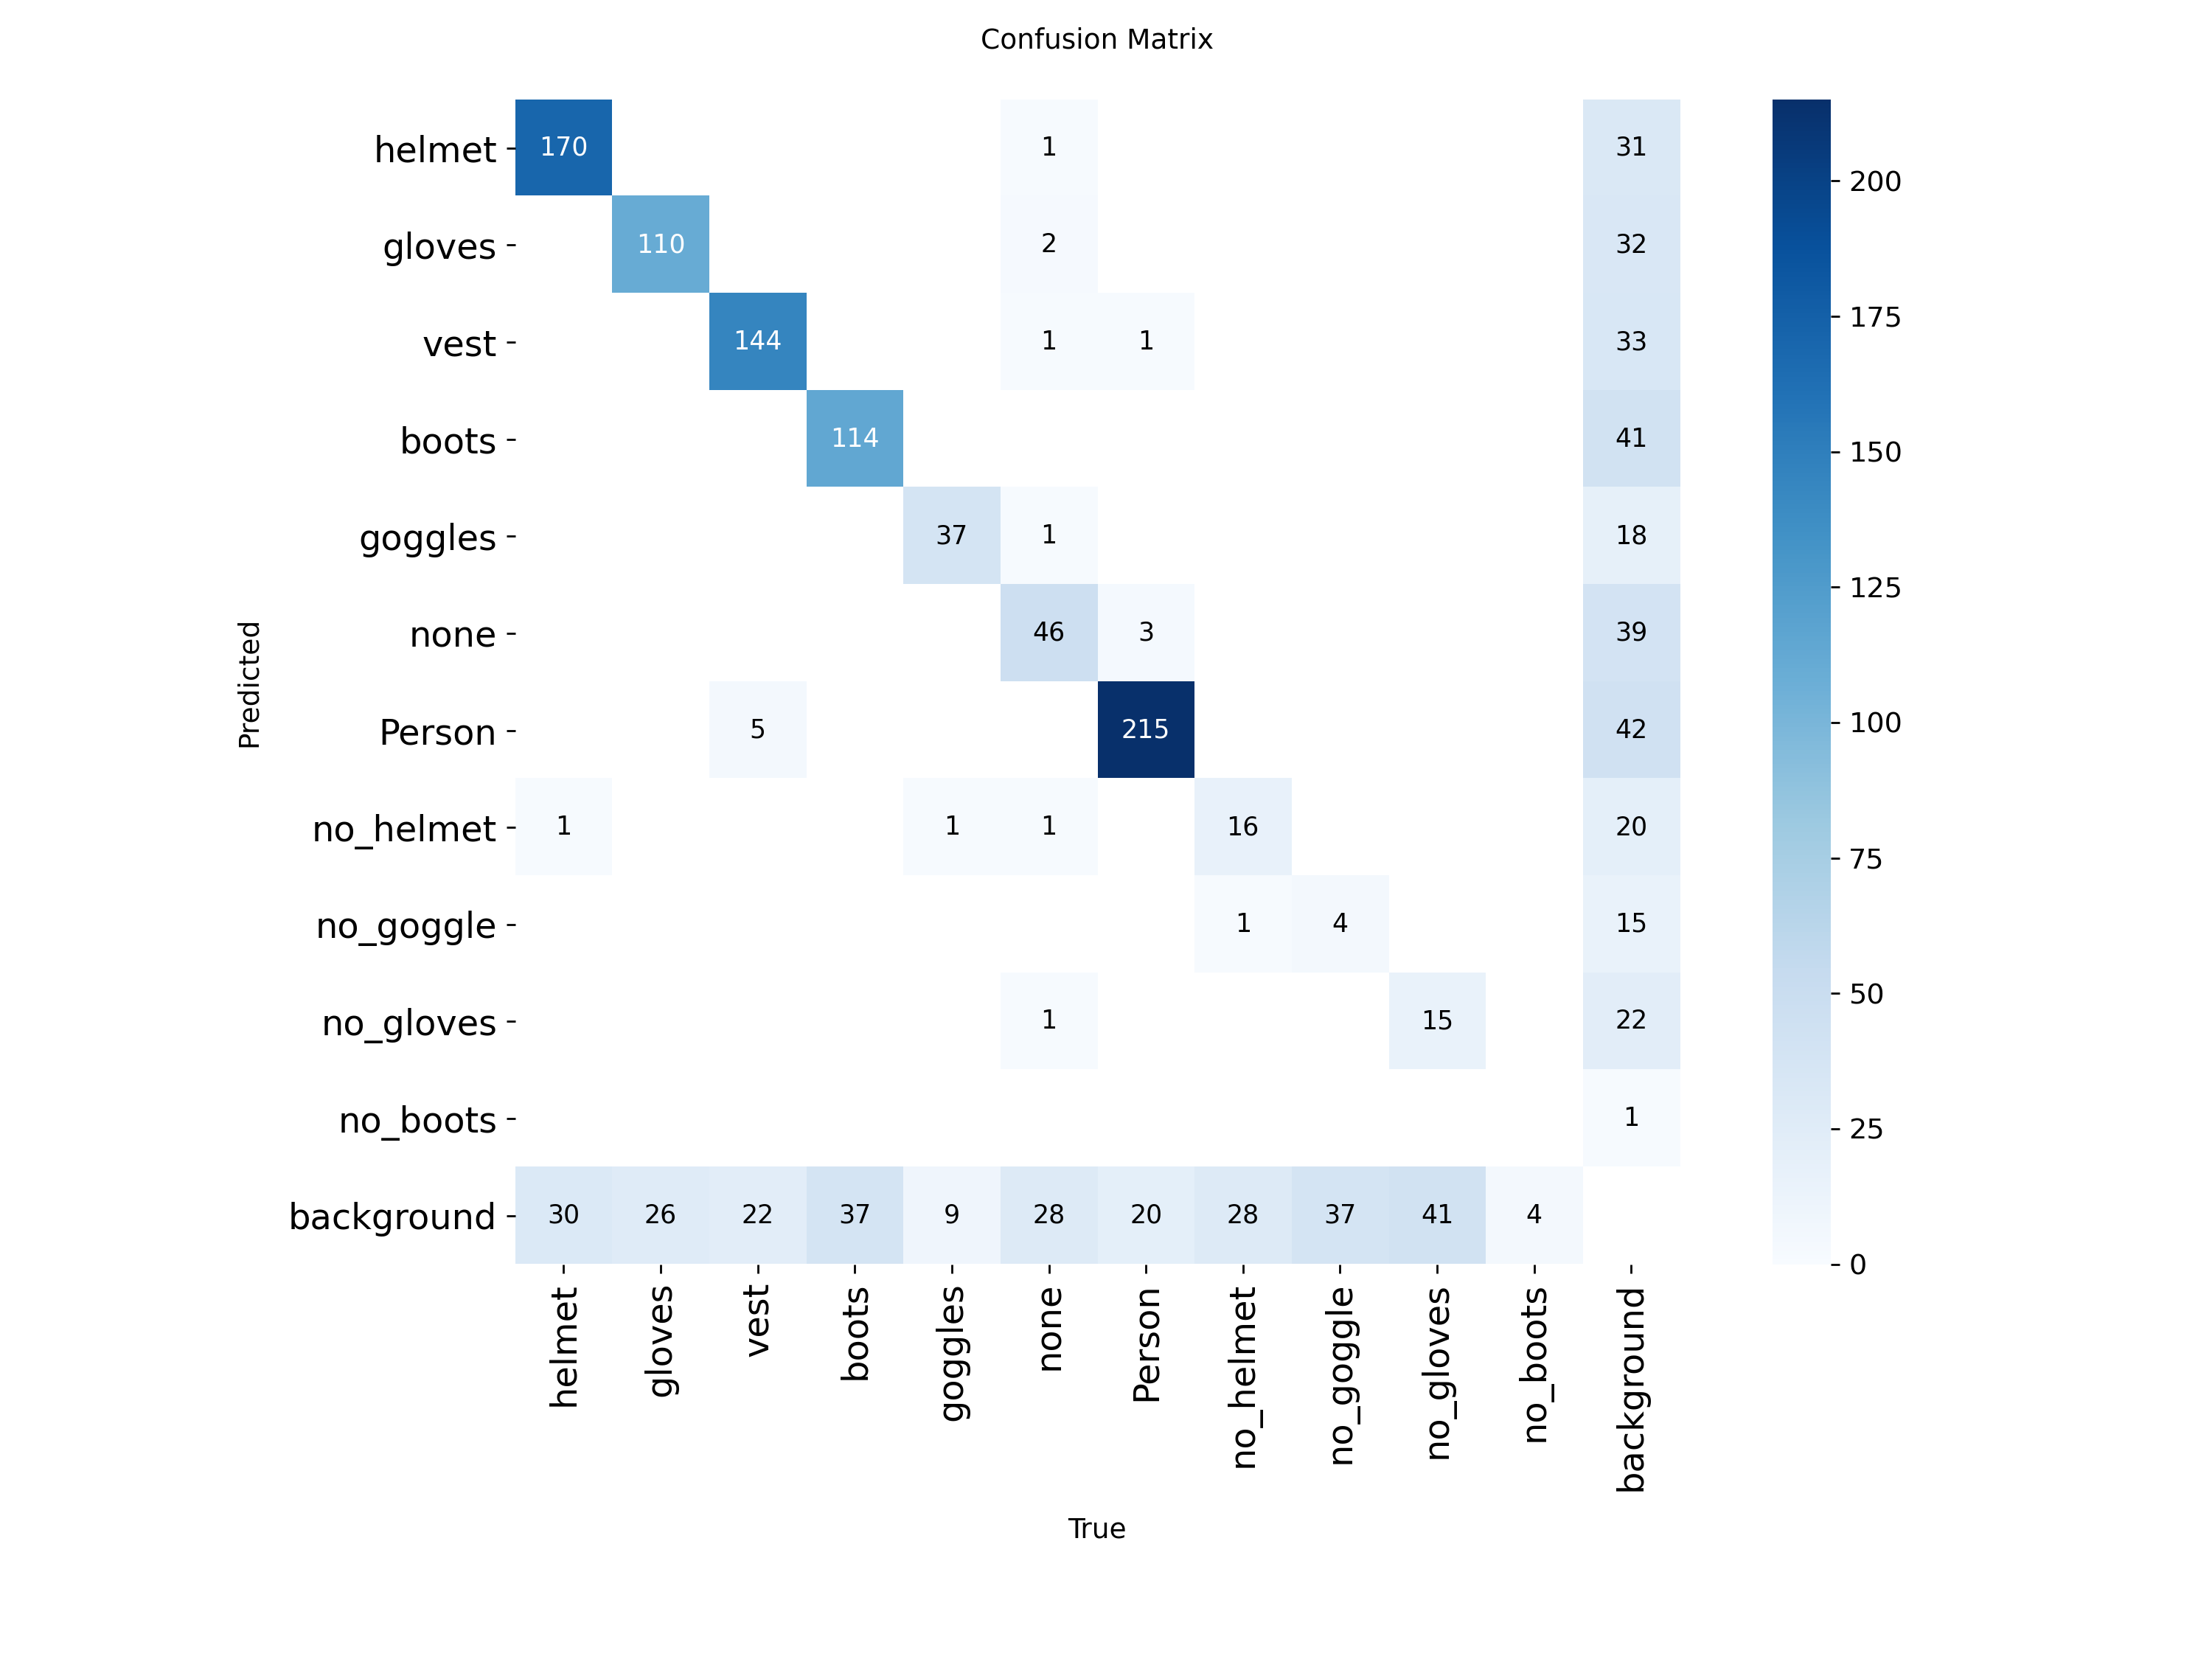

--- Confusion Matrix (Normalized) ---


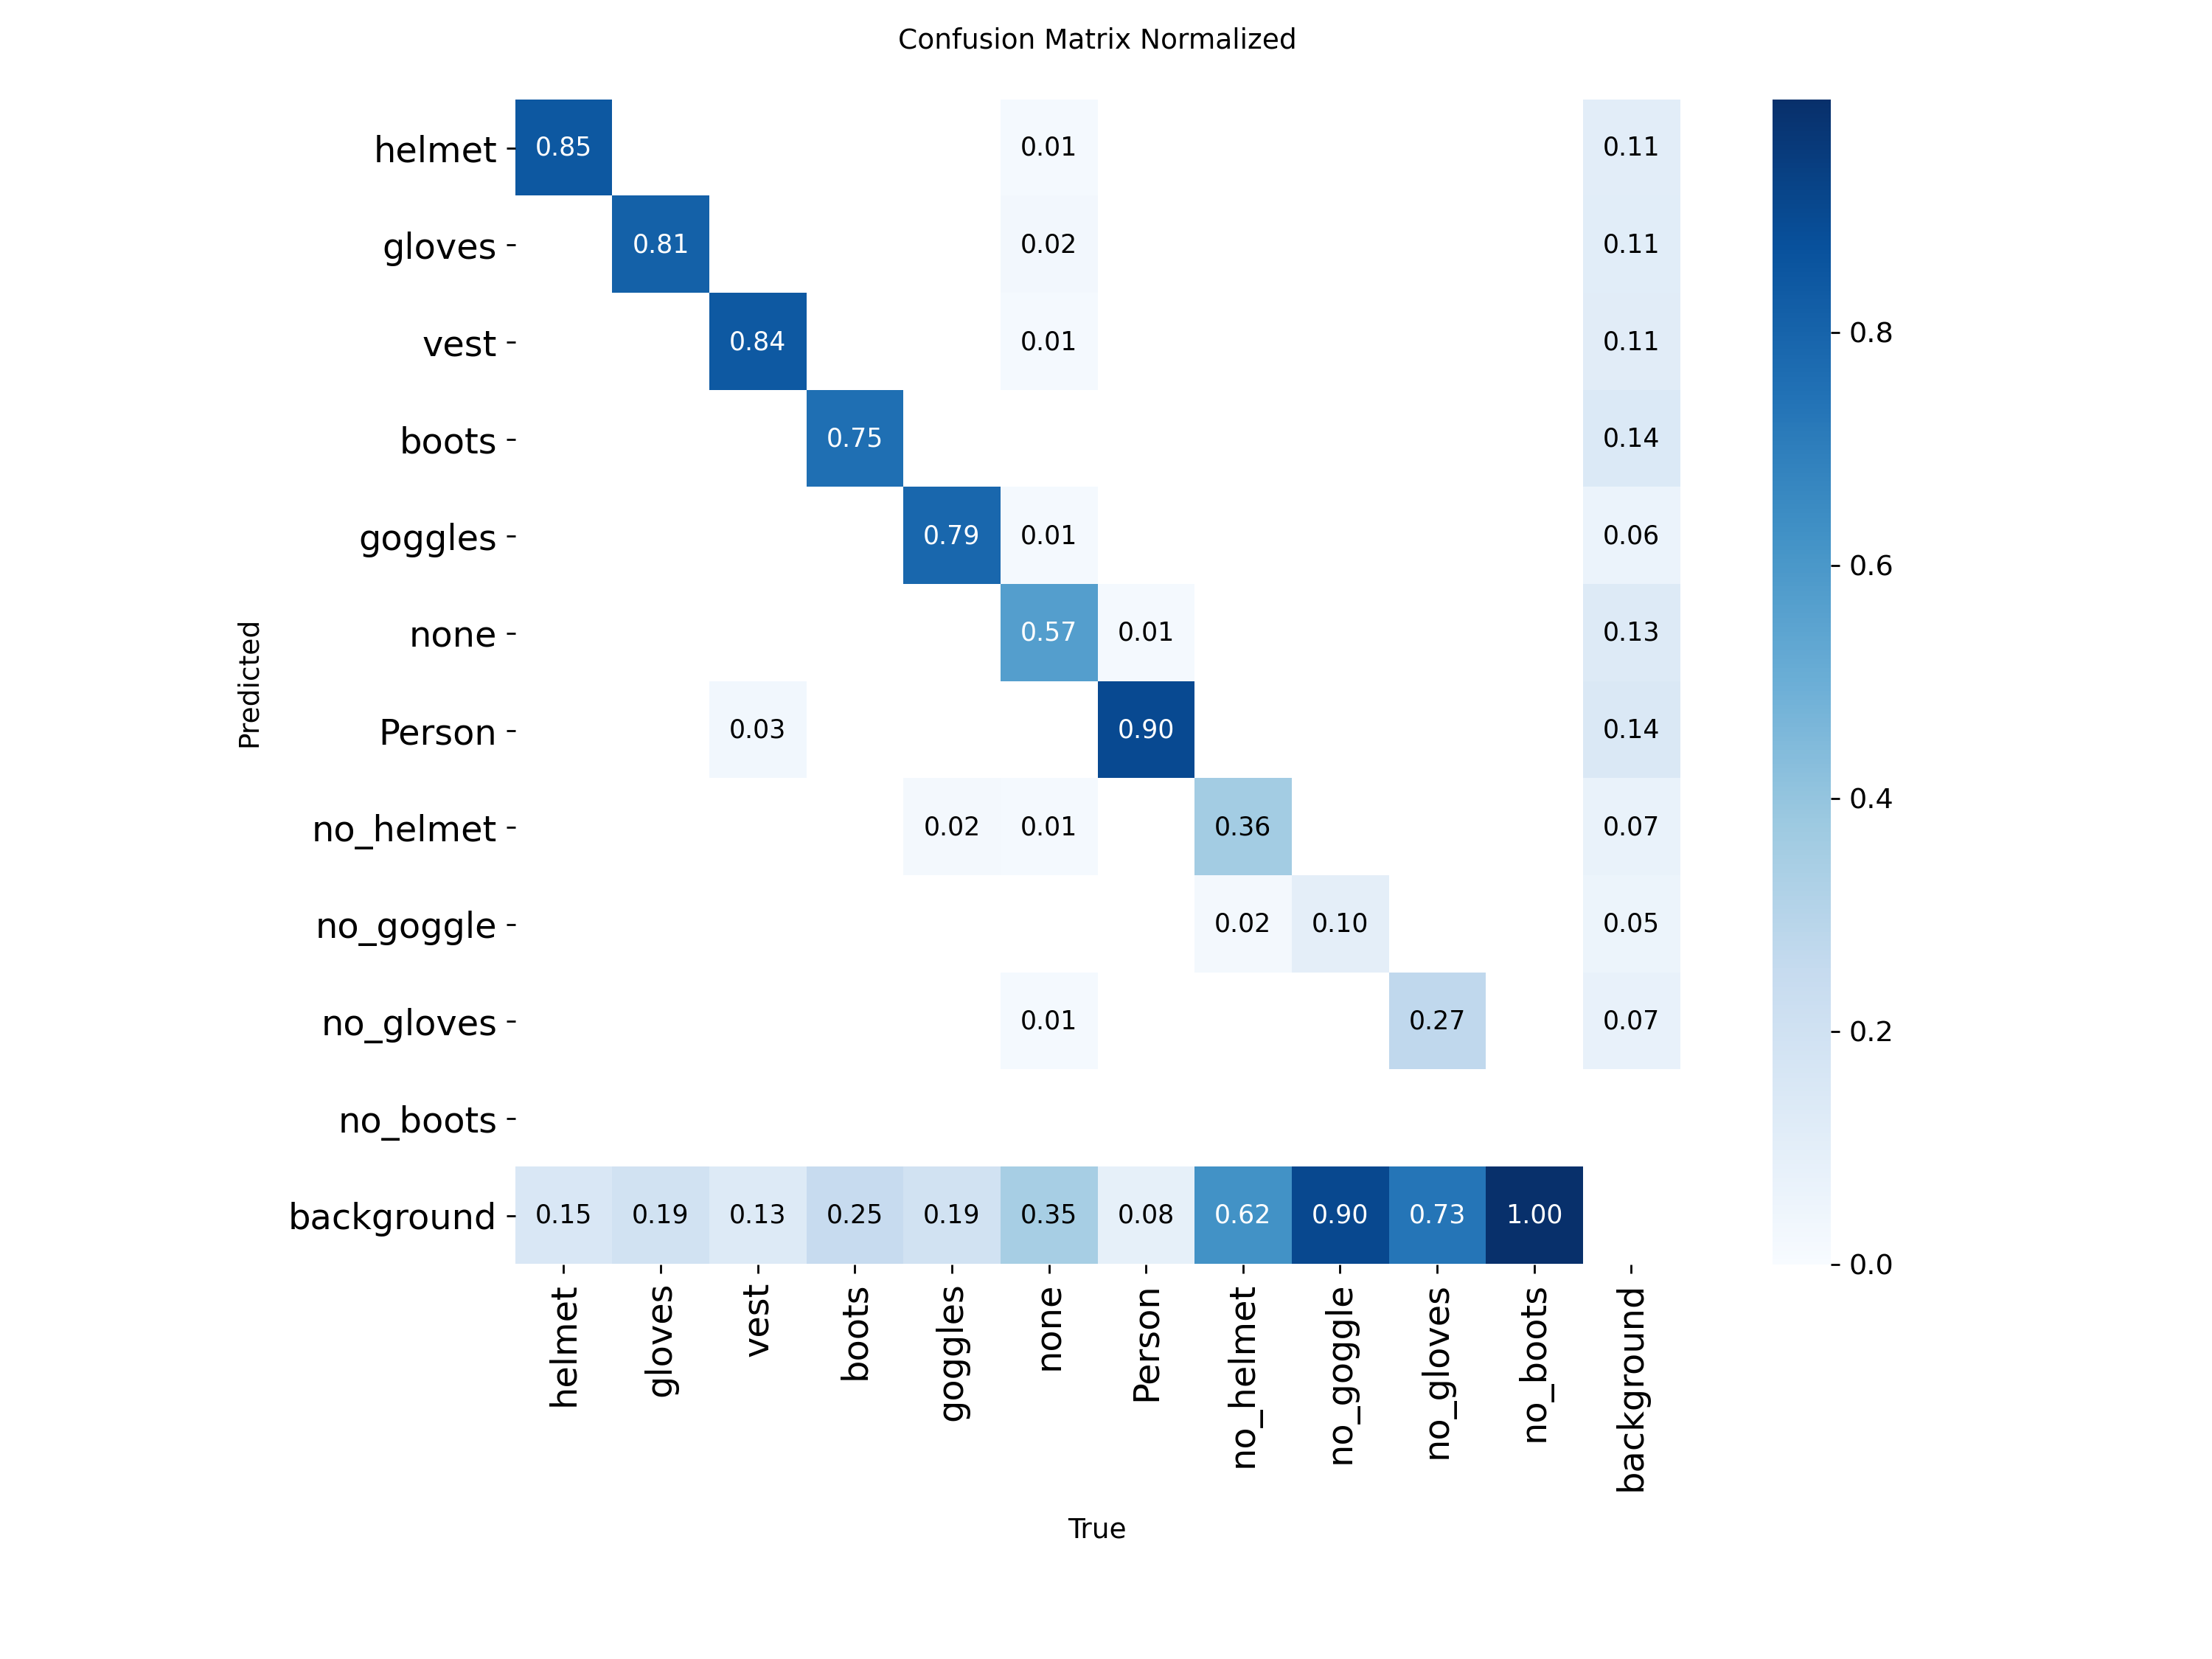

  [PR_curve.png] not yet available.
  [F1_curve.png] not yet available.
--- Validation Batch Predictions ---


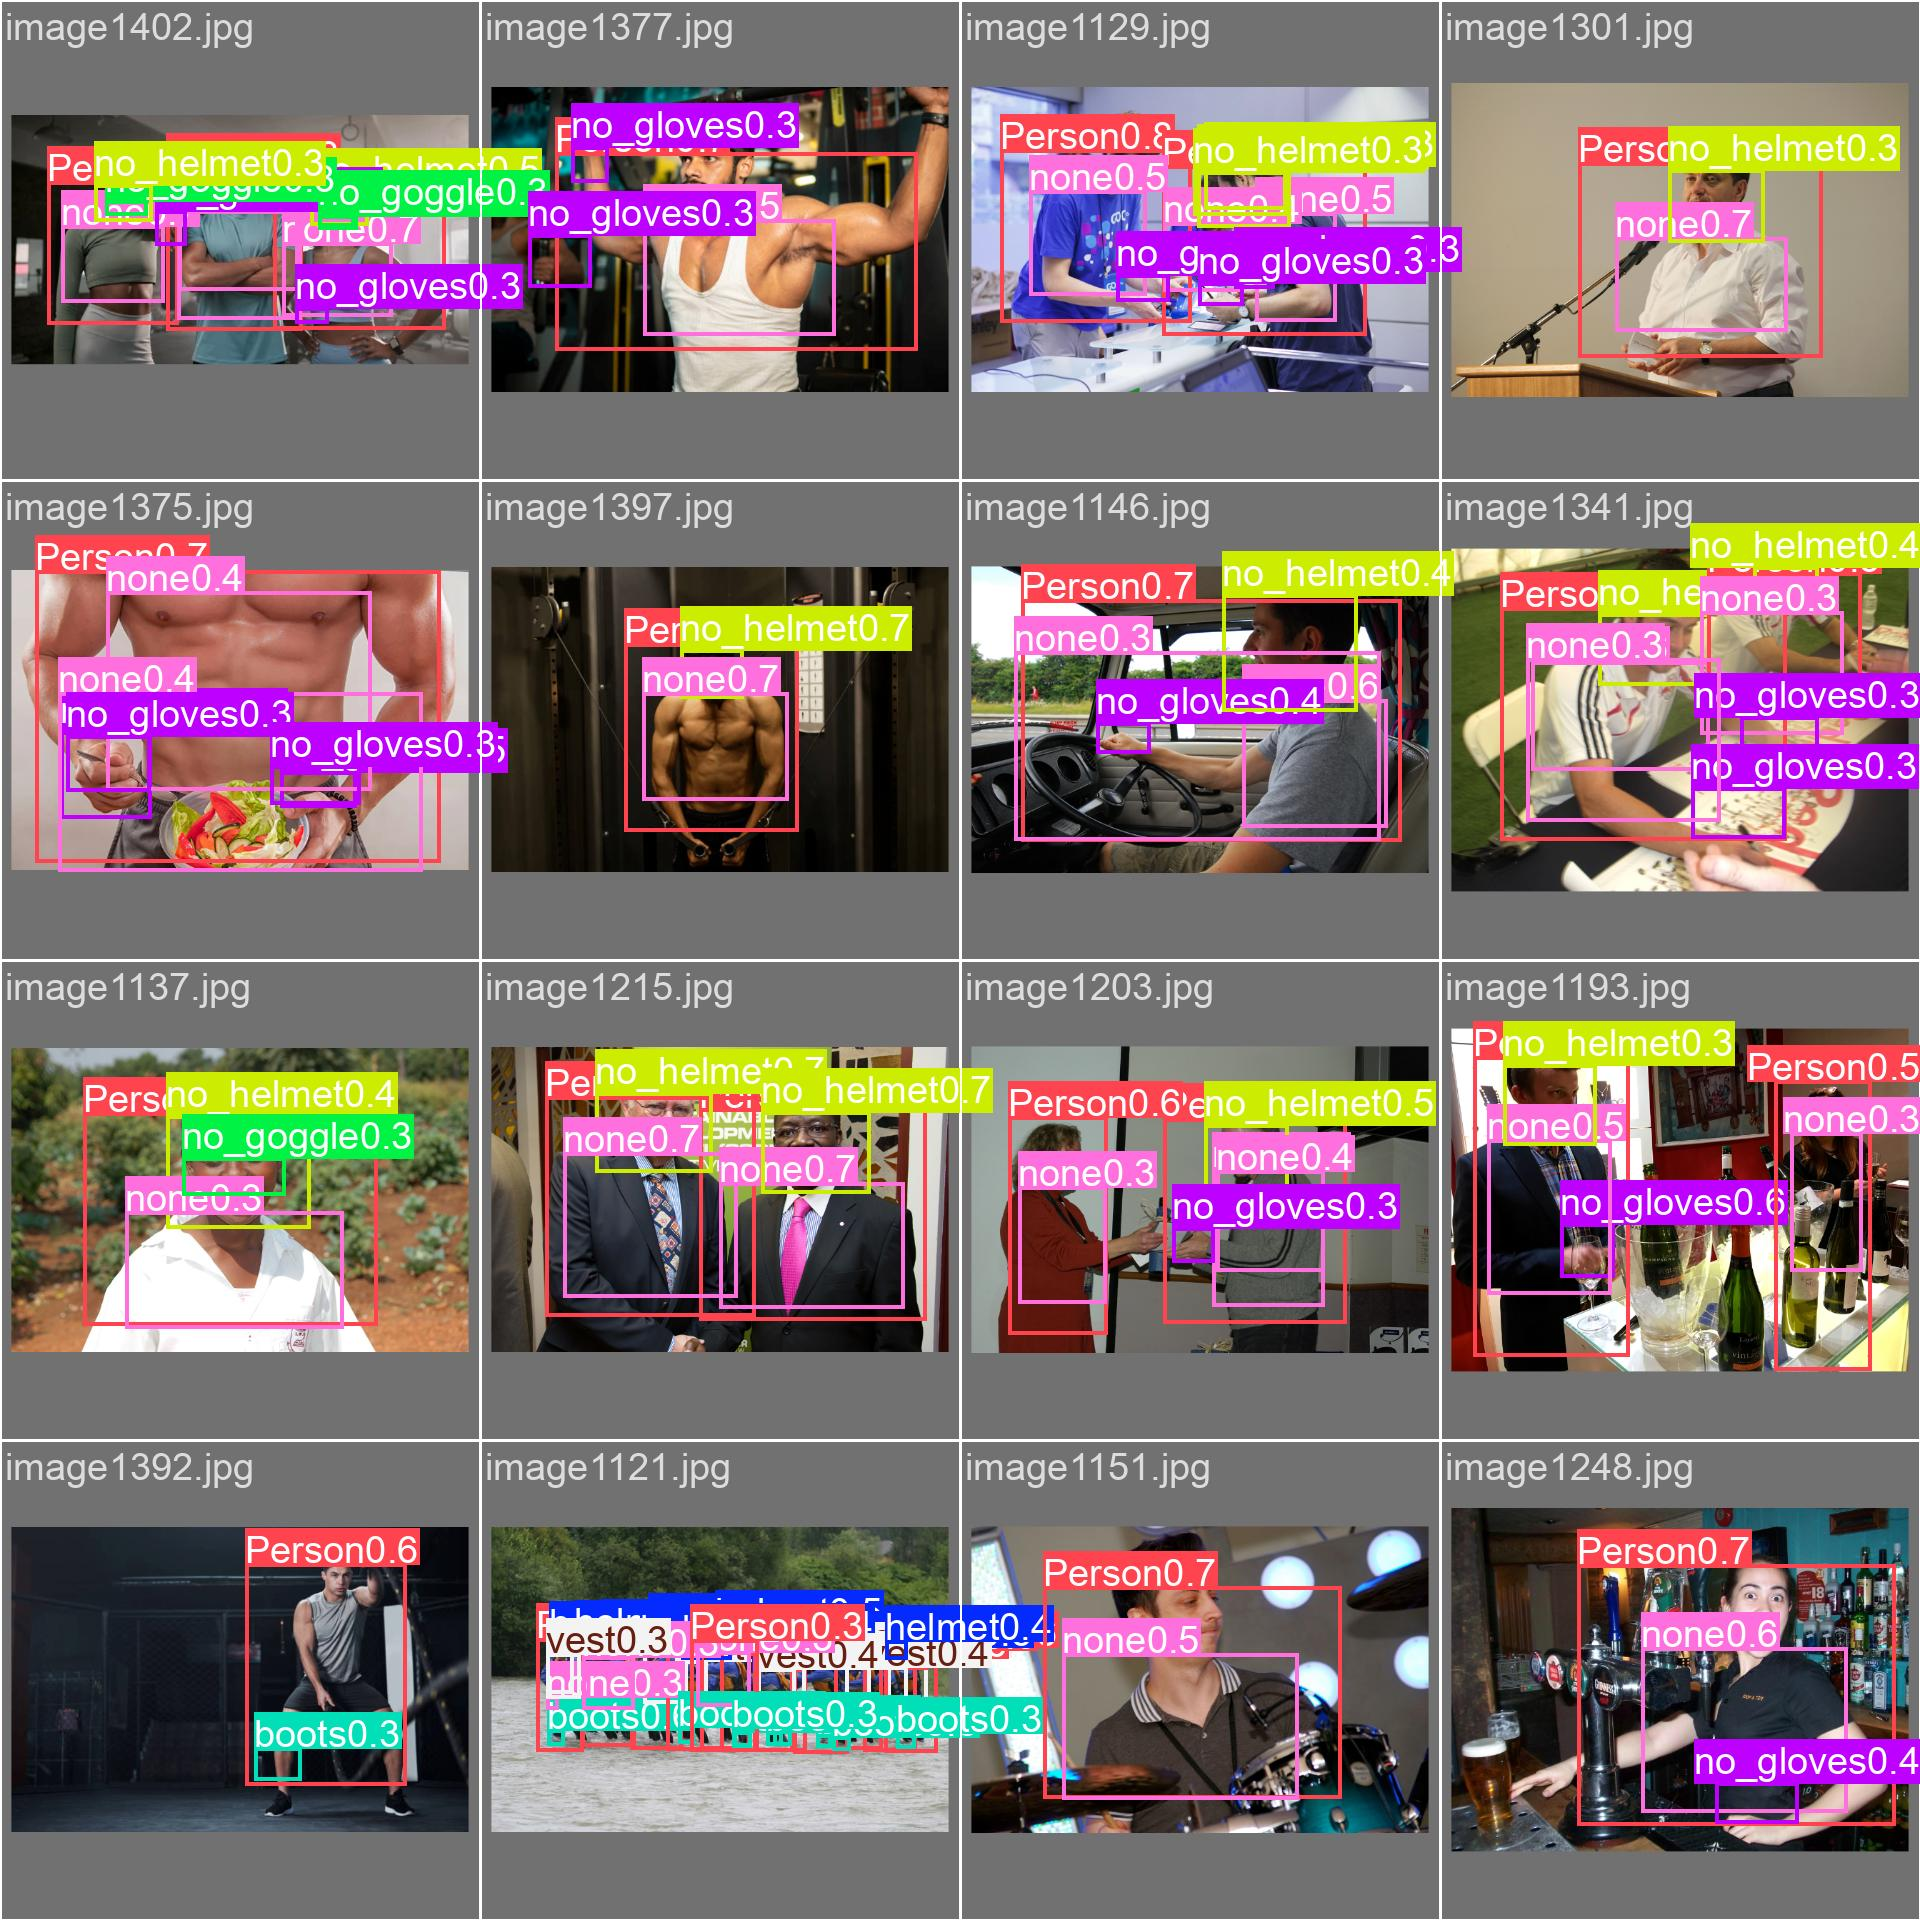

--- Validation Ground Truth ---


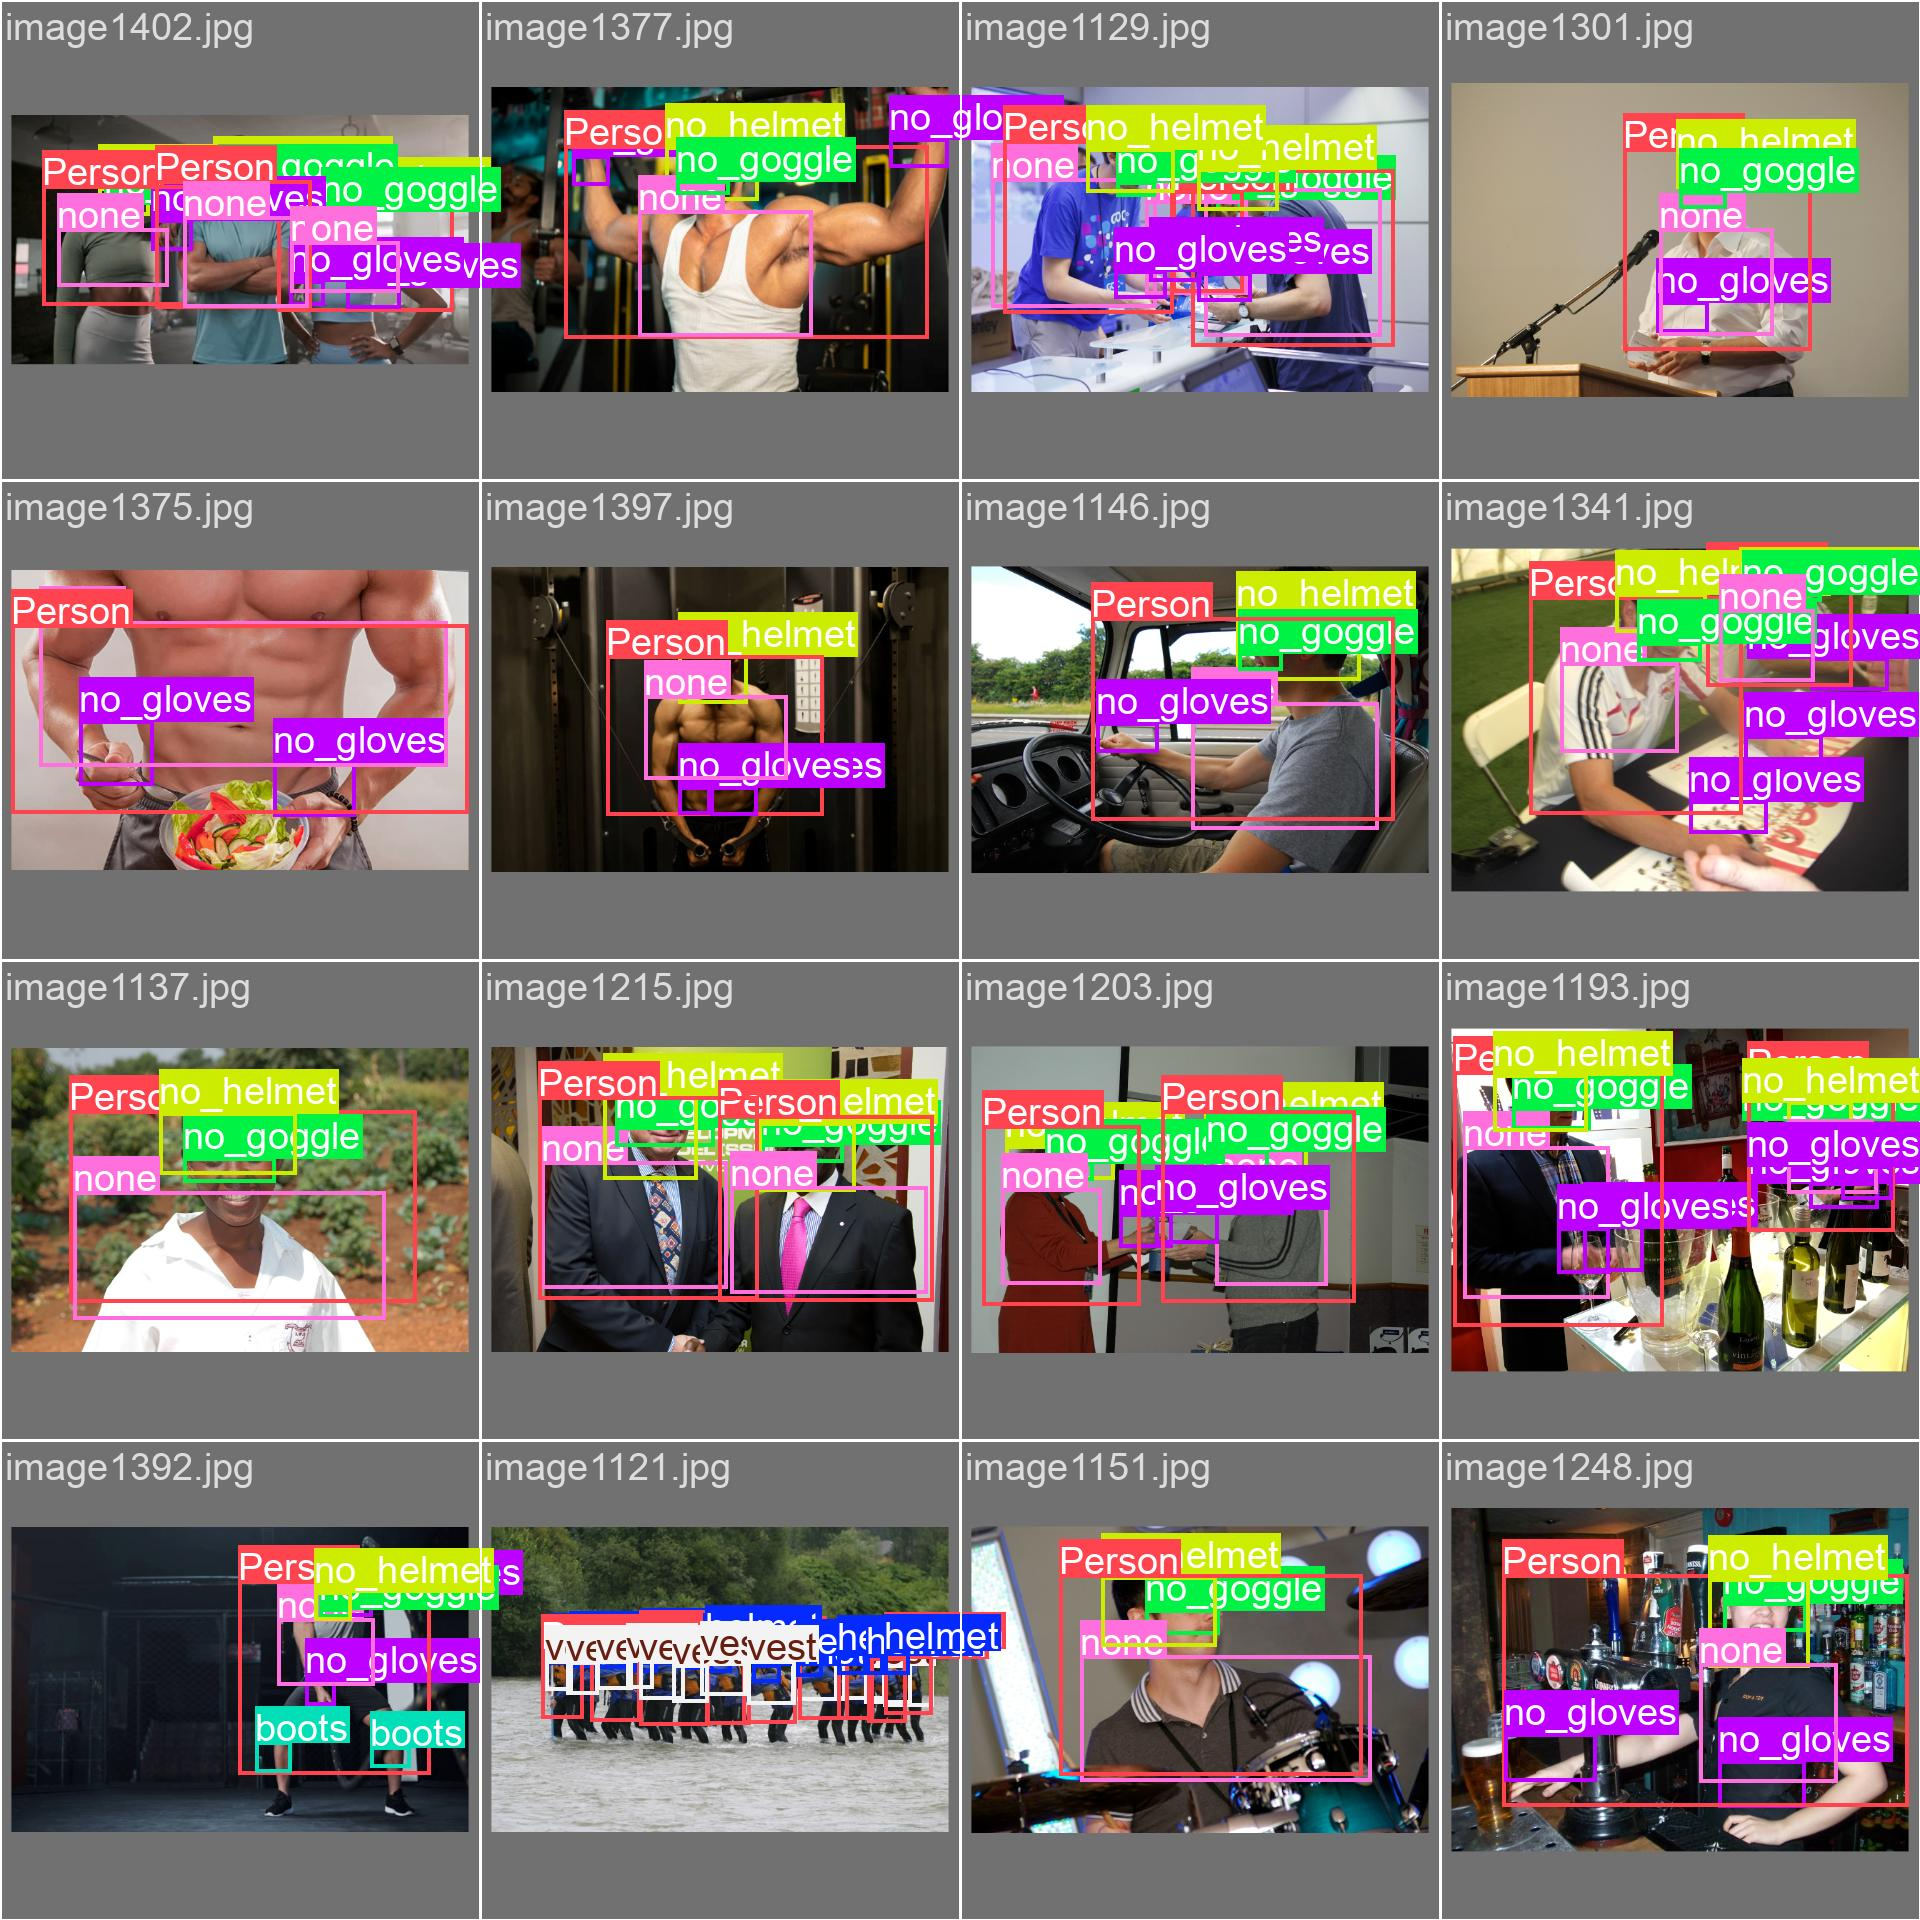

In [10]:
# ============================================================
# CELL 8: Display all plots from both run dirs
# ============================================================
from IPython.display import Image, display
import os, shutil

PLOT_FILES = [
    ('results.png',                   'Training History (Loss + mAP)'),
    ('confusion_matrix.png',          'Confusion Matrix'),
    ('confusion_matrix_normalized.png','Confusion Matrix (Normalized)'),
    ('PR_curve.png',                  'Precision-Recall Curve'),
    ('F1_curve.png',                  'F1 Score Curve'),
    ('val_batch0_pred.jpg',           'Validation Batch Predictions'),
    ('val_batch0_labels.jpg',         'Validation Ground Truth'),
]

for exp_dir, exp_label in [(EXP1_DRIVE_DIR, 'Exp1 YOLOv8n'),
                            (EXP2_DRIVE_DIR, 'Exp2 YOLOv8s')]:
    print(f'\n{"="*55}')
    print(f' {exp_label}')
    print(f'{"="*55}')
    found = 0
    for fname, title in PLOT_FILES:
        path = f'{exp_dir}/{fname}'
        if os.path.exists(path):
            found += 1
            print(f'--- {title} ---')
            display(Image(filename=path, width=850))
            # Backup to plots dir
            shutil.copy2(path, f'{DRIVE_PLOTS_DIR}/{exp_label.replace(" ","_")}_{fname}')
        else:
            print(f'  [{fname}] not yet available.')
    if found == 0:
        print('  No plots yet — run Cells 4/5 first.')

---
## Cell 9 — Validation Inference + Speed Benchmark

Running inference on val set...

0: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 5.1ms
1: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 5.1ms
2: 640x640 1 none, 1 Person, 5.1ms
3: 640x640 1 none, 1 Person, 5.1ms
4: 640x640 3 nones, 3 Persons, 5.1ms
5: 640x640 1 helmet, 1 vest, 1 Person, 5.1ms
Speed: 2.7ms preprocess, 5.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/PPE_Research/phase1/yolov8n_baseline/inference/val_preds

Detections:
  Image 1: ['vest', 'helmet', 'goggles', 'Person', 'boots', 'boots', 'gloves', 'gloves']  conf=['0.84', '0.83', '0.80', '0.78', '0.77', '0.77', '0.69', '0.64']
  Image 2: ['boots', 'helmet', 'boots', 'vest', 'Person', 'gloves', 'goggles', 'gloves']  conf=['0.86', '0.82', '0.82', '0.78', '0.78', '0.77', '0.64', '0.61']
  Image 3: ['Person', 'none']  conf=['0.73', '0.59']
  Image 4: ['Person', 'none']  conf=['0.57', '0.48']
  Image 5: ['Person', 'Person

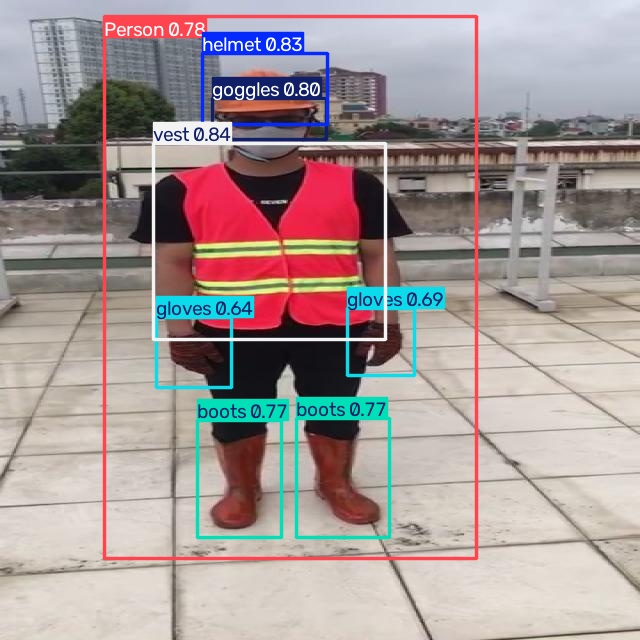

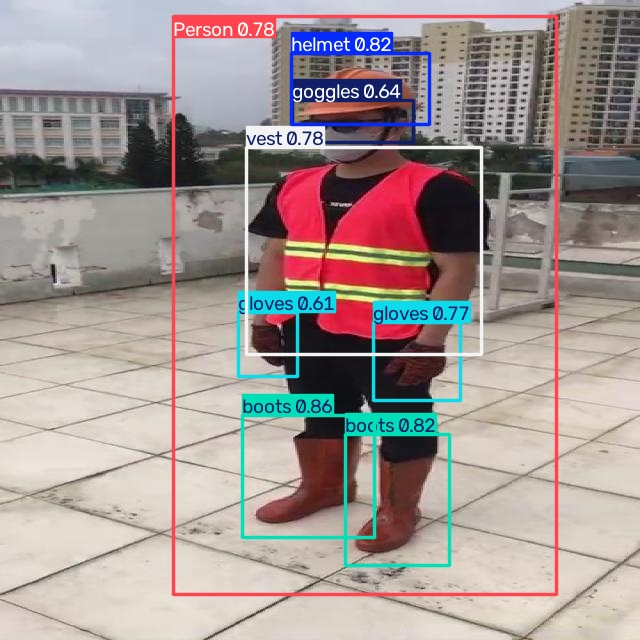

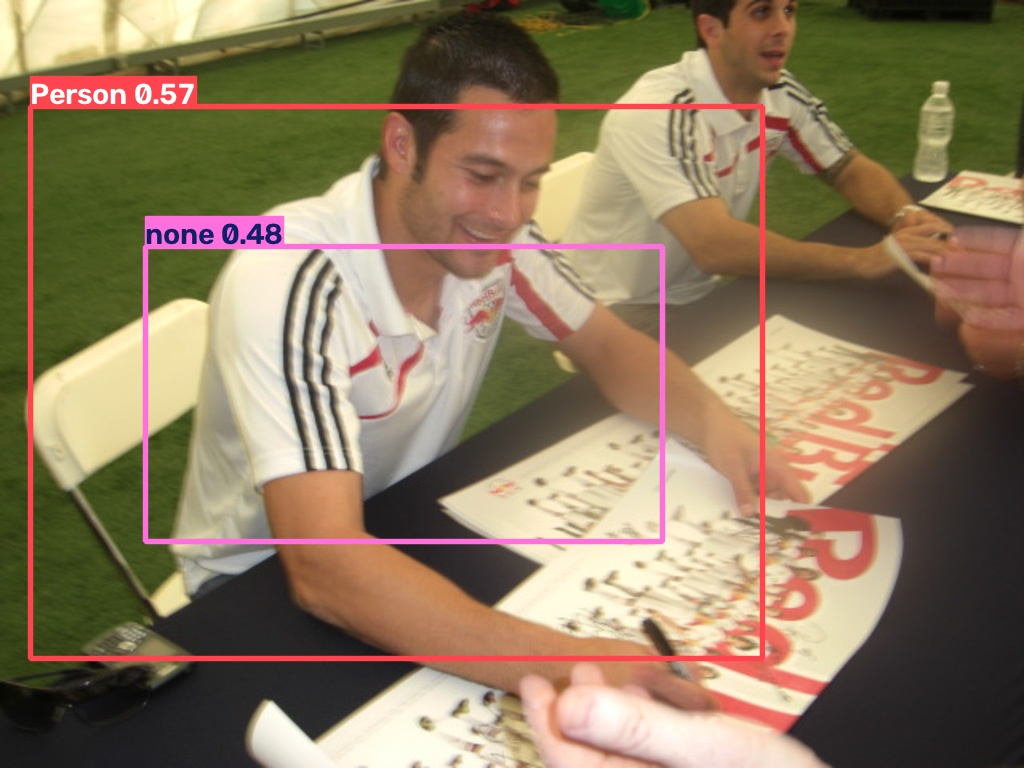


Hard Negative Manual Checklist (test with phone photos):
  [ ] Baseball cap       → must NOT be classified as helmet
  [ ] Hoodie with hood   → must NOT be classified as helmet
  [ ] Beanie / knit hat  → must NOT be classified as helmet
  [ ] Sunglasses         → must NOT be classified as goggles
  [ ] Reflective bag     → check vest false positives

Speed Benchmark (50 runs on dummy 640×640 frame)...
  Avg    : 10.14 ms/frame  (98.6 FPS)
  p95    : 11.67 ms/frame
  Target on Hailo-8L : 15-25 FPS (INT8 NPU)
Saved: /content/drive/MyDrive/PPE_Research/phase1/metrics/exp1_speed_benchmark.json


In [11]:
# ============================================================
# CELL 9: Validation inference + speed benchmark
# ============================================================
import numpy as np, time, glob, json
from ultralytics import YOLO
from IPython.display import Image, display

best_pt = f'{EXP1_DRIVE_DIR}/weights/best.pt'
if not os.path.exists(best_pt):
    print('best.pt not found. Run Cell 4 first.'); exit()

model_eval = YOLO(best_pt)

# ── Inference on val images ──────────────────────────────────
print('Running inference on val set...')
val_dir = next((d for d in [
    '/root/.config/Ultralytics/DVC/datasets/construction-ppe/images/val',
    'datasets/construction-ppe/images/val'] if os.path.isdir(d)), None)

if val_dir:
    val_imgs = glob.glob(f'{val_dir}/*.jpg')[:6]
    inf_res = model_eval.predict(
        source=val_imgs, conf=0.40, iou=0.45,
        save=True, project=f'{EXP1_DRIVE_DIR}/inference', name='val_preds', exist_ok=True
    )
    print('\nDetections:')
    for i, r in enumerate(inf_res):
        if r.boxes is not None and len(r.boxes):
            dets = [model_eval.names[int(c)] for c in r.boxes.cls.cpu()]
            confs = [f'{c:.2f}' for c in r.boxes.conf.cpu()]
            print(f'  Image {i+1}: {dets}  conf={confs}')
        else:
            print(f'  Image {i+1}: no detections')

    # Display first 3 predictions
    pred_dir = f'{EXP1_DRIVE_DIR}/inference/val_preds'
    for img in sorted(glob.glob(f'{pred_dir}/*.jpg'))[:3]:
        display(Image(filename=img, width=700))
else:
    print('Val dir not found — run inference on your own images below.')

# ── Hard negative checklist ──────────────────────────────────
print()
print('Hard Negative Manual Checklist (test with phone photos):')
print('  [ ] Baseball cap       → must NOT be classified as helmet')
print('  [ ] Hoodie with hood   → must NOT be classified as helmet')
print('  [ ] Beanie / knit hat  → must NOT be classified as helmet')
print('  [ ] Sunglasses         → must NOT be classified as goggles')
print('  [ ] Reflective bag     → check vest false positives')

# ── Speed benchmark ──────────────────────────────────────────
print()
print('Speed Benchmark (50 runs on dummy 640×640 frame)...')
dummy = np.zeros((640, 640, 3), dtype=np.uint8)
for _ in range(5): model_eval.predict(dummy, verbose=False)  # warmup
times = []
for _ in range(50):
    t0 = time.perf_counter()
    model_eval.predict(dummy, verbose=False)
    times.append((time.perf_counter()-t0)*1000)
print(f'  Avg    : {np.mean(times):.2f} ms/frame  ({1000/np.mean(times):.1f} FPS)')
print(f'  p95    : {np.percentile(times,95):.2f} ms/frame')
print(f'  Target on Hailo-8L : 15-25 FPS (INT8 NPU)')

speed = {'avg_ms': round(np.mean(times),2), 'p95_ms': round(np.percentile(times,95),2),
         'fps': round(1000/np.mean(times),1),
         'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}
with open(f'{DRIVE_METRICS_DIR}/exp1_speed_benchmark.json','w') as f:
    json.dump(speed, f, indent=2)
print(f'Saved: {DRIVE_METRICS_DIR}/exp1_speed_benchmark.json')

---
## Cell 10 — Phase Gate Check & Final Summary

In [ ]:
# ============================================================
# CELL 10: Phase gate check + Drive verification
# ============================================================
import json, os
from datetime import datetime

def read_best(run_dir):
    csv = f'{run_dir}/results.csv'
    if not os.path.exists(csv): return {}
    df = pd.read_csv(csv); df.columns = df.columns.str.strip()
    bi = df['metrics/mAP50(B)'].idxmax(); br = df.iloc[bi]
    return {'mAP50': float(br['metrics/mAP50(B)']),
            'epochs': int(df['epoch'].iloc[-1]),
            'best_epoch': int(br['epoch'])}

r1 = read_best(EXP1_DRIVE_DIR)
r2 = read_best(EXP2_DRIVE_DIR)

summary = {
    'phase': 1,
    'completed_at': datetime.now().isoformat(),
    'experiments': {
        'exp1_yolov8n': m1 if 'm1' in dir() else r1,
        'exp2_yolov8s': m2 if 'm2' in dir() else r2,
    },
    'phase1_gate': {
        'target_mAP50'         : 0.70,
        'exp1_passed'          : r1.get('mAP50', 0) >= 0.70,
        'exp2_passed'          : r2.get('mAP50', 0) >= 0.70,
        'aggregate_gate_passed': r1.get('mAP50', 0) >= 0.70 or r2.get('mAP50', 0) >= 0.70,
        'proceed_to_phase3'    : True,
        'proceed_basis'        : (
            'Proceeds on PPE-present capability plus the Phase 6 spatial '
            'compliance engine; aggregate mAP50 is expected to rise with '
            'Phase 4 site-specific fine-tuning.'
        ),
    }
}

with open(f'{DRIVE_PHASE1_DIR}/phase1_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print('=' * 60)
print(' PHASE 1 GATE CHECK')
print('=' * 60)
print(f'  Target mAP50     : >= 0.70')
print(f'  YOLOv8n mAP50    : {r1.get("mAP50", "not run")}')
print(f'  YOLOv8s mAP50    : {r2.get("mAP50", "not run")}')
print()
if summary['phase1_gate']['aggregate_gate_passed']:
    print('  GATE PASSED — Proceed to Phase 3 (Real-World Validation)')
    print('  Use best.pt from the experiment with higher mAP50.')
else:
    print('  GATE NOT PASSED')
    print('  If training is incomplete: re-run Cell 4 (will resume from checkpoint).')
    print('  Proceeding to Phase 3 on PPE-present capability + spatial compliance engine.')

print()
print('Drive contents:')
for root, _, files in os.walk(DRIVE_PHASE1_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        rel  = os.path.relpath(full, DRIVE_PROJECT_ROOT)
        mb   = os.path.getsize(full)/1e6
        print(f'  {rel}  ({mb:.2f} MB)')

---
## Cell 11 — Download Key Files to Local Machine

In [12]:
# ============================================================
# CELL 11: Download for Git commit
# ============================================================
from google.colab import files

to_download = [
    (f'{DRIVE_PHASE1_DIR}/phase1_summary.json',         'phase1_summary.json'),
    (f'{DRIVE_METRICS_DIR}/phase1_metrics.json',        'phase1_metrics.json'),
    (f'{EXP1_DRIVE_DIR}/results.csv',                   'results_exp1_yolov8n.csv'),
    (f'{EXP2_DRIVE_DIR}/results.csv',                   'results_exp2_yolov8s.csv'),
    (f'{DRIVE_PLOTS_DIR}/phase1_training_curves.png',   'phase1_training_curves.png'),
    (f'{DRIVE_METRICS_DIR}/exp1_speed_benchmark.json',  'exp1_speed_benchmark.json'),
]

print('Downloading files for local Git commit...')
print('After download, copy to notebooks/ in your local repo.')
print()
for src, label in to_download:
    if os.path.exists(src):
        print(f'  Downloading: {label}')
        files.download(src)
    else:
        print(f'  Not ready:   {label}')

After download, copy to notebooks/ in your local repo.

  Downloading: phase1_summary.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Downloading: phase1_metrics.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

  Downloading: exp1_speed_benchmark.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>